# Prediksi Grade Nutri-Score (A–E) pada Produk Makanan Kemasan
### Proyek Supervised Learning : analisis data - model serving

**Disusun sebagai proyek pembelajaran mandiri oleh mahasiswa Sains Data: Dzaki Rafif Fakhriyanto.** Fokus notebook ini adalah memahami bagaimana data nutrisi dan informasi produk dapat digunakan untuk memperkirakan grade Nutri-Score A–E menggunakan beberapa metode klasifikasi.

> **Batasan penting:** model pada proyek ini adalah *estimator* yang mempelajari pola dari label pada dataset. Fitur poin Nutri-Score yang dibuat di notebook merupakan pendekatan sederhana untuk membantu model, bukan implementasi lengkap algoritma resmi Nutri-Score dan bukan pengganti penilaian resmi produk.

## Gambaran masalah
Informasi gizi pada produk makanan terdiri dari banyak kolom, seperti energi, gula, lemak, protein, serat, dan natrium. Proyek ini mencoba menjawab apakah kombinasi informasi tersebut, ditambah kategori produk, dapat digunakan untuk memperkirakan grade Nutri-Score yang tercatat pada dataset.

## Pertanyaan penelitian
1. Seberapa baik grade A–E dapat diprediksi dari kandungan gizi, kategori produk, dan informasi alergen?
2. Apakah fitur turunan seperti rasio nutrisi dan poin pendekatan Nutri-Score membantu model?
3. Karena grade A–E memiliki urutan, apakah model ordinal memberikan hasil lebih baik daripada klasifikasi biasa?
4. Pada kelas atau kategori produk mana model masih sering melakukan kesalahan?

## Mengapa dataset ini digunakan?
Dataset master berisi informasi produk makanan kemasan, label Nutri-Score, kategori produk, dan sejumlah kandungan gizi per 100 gram. Kolom-kolom tersebut sesuai dengan tujuan proyek karena menyediakan **fitur sebagai masukan** dan **grade A–E sebagai target**. Informasi nama produk dan merek juga memungkinkan pembagian data berdasarkan grup agar varian produk yang mirip tidak tersebar secara sembarangan di data latih dan data uji.

Notebook menggunakan tabel `nutriscore_master` yang sudah disiapkan dari dua berkas sumber (`foods_health_scores_allergens` dan `foods_dietary_restrictions`). Proses penggabungan sumber tersebut tidak dibangun ulang di notebook ini; notebook dimulai dari tabel master atau CSV hasil integrasi.

## Hasil yang ingin diperoleh
- Ringkasan kualitas data dan catatan keputusan pembersihan.
- Perbandingan beberapa model klasifikasi dengan *group-stratified cross-validation*.
- Model terpilih dan evaluasi akhir pada data uji yang dipisahkan berdasarkan grup produk-merek.
- Analisis kontribusi fitur dan pola kesalahan prediksi.
- Artefak model, metadata eksperimen, dan contoh endpoint FastAPI.

## Alur pengerjaan
`Setup → Memuat Data → Audit → Cleaning → Feature Engineering → EDA & Statistik → Group Split → Pipeline → Baseline & CV → Tuning → Model Ordinal/Ensemble → Test Evaluation → Ablation → Feature Importance → Error Analysis → Simpan Model & Contoh API`

## Prinsip analisis
- Data uji tidak digunakan untuk memilih model; pemilihan dilakukan dari data latih.
- Imputasi, encoding, dan scaling ditempatkan di dalam `Pipeline` agar dipelajari pada bagian data latih setiap fold.
- Produk dengan kombinasi nama dan merek yang sama ditempatkan pada grup yang sama saat pembagian data.
- Setiap keputusan cleaning dicatat dan dijelaskan.
- Hasil model dibaca bersama keterbatasan data; nilai metrik yang baik tidak otomatis berarti model sudah sesuai untuk penggunaan resmi.

## 1. Setup & Konfigurasi

**Tujuan:** menyiapkan library, urutan kelas A–E, *random seed*, dan folder keluaran.

**Mengapa dilakukan:** hasil eksperimen perlu dapat diulang dengan pengaturan yang sama. Urutan kelas juga harus konsisten karena grade A–E bersifat berurutan.

**Output yang diharapkan:** informasi versi Python/library dan folder `outputs_nutriscore/` yang siap digunakan.

In [1]:
import os, sys, json, warnings, platform  # modul sistem, JSON, peringatan, info platform
import numpy as np  # operasi numerik
import pandas as pd  # manipulasi tabel
import matplotlib.pyplot as plt  # visualisasi dasar
import seaborn as sns  # visualisasi statistik
import sqlite3  # membaca database SQLite hasil integrasi
import joblib  # menyimpan model
import sklearn  # untuk mencatat versi sklearn
from scipy import stats  # uji statistik (Kruskal-Wallis, Spearman)
warnings.filterwarnings("ignore")  # sembunyikan peringatan agar output rapi
pd.set_option("display.max_columns", 60)  # tampilkan semua kolom tabel
pd.set_option("display.width", 200)  # lebar tampilan tabel
sns.set_theme(style="whitegrid", context="notebook")  # tema grafik seragam
SEED = 42  # seed global untuk reproduksibilitas
np.random.seed(SEED)  # kunci seed numpy
GRADES = ["A", "B", "C", "D", "E"]  # urutan grade dari terbaik ke terburuk
GRADE_TO_INT = {g: i for i, g in enumerate(GRADES)}  # pemetaan grade ke angka ordinal
OUT_DIR = "outputs_nutriscore"  # folder keluaran model dan laporan
os.makedirs(OUT_DIR, exist_ok=True)  # buat folder bila belum ada
print("Python", platform.python_version(), "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)  # catat versi

Python 3.13.18 | pandas 2.2.3 | scikit-learn 1.6.1


### Interpretasi output
Output versi Python dan library mencatat lingkungan yang digunakan saat eksperimen. `SEED = 42` menjaga proses acak agar hasil lebih mudah diulang pada lingkungan yang sama. Folder `outputs_nutriscore/` menjadi tempat menyimpan model dan laporan. Perbedaan versi library dapat memengaruhi hasil atau kompatibilitas file model, sehingga versi ini perlu dicatat.

### 1b. Membuat Modul Fitur (`nutriscore_utils.py`)

**Tujuan:** memisahkan fungsi normalisasi, pembersihan nilai nutrisi, rekayasa fitur, rumus poin pendekatan, dan classifier ordinal dari notebook utama.

**Mengapa dilakukan:** fungsi yang sama perlu dipakai saat training dan saat model dipanggil melalui API. Pemisahan ini juga membuat kode lebih mudah diperiksa dan diuji.

**Output yang diharapkan:** file `nutriscore_utils.py` yang dapat diimpor kembali. Fungsi pada modul ini bekerja per baris; parameter seperti median imputasi tetap dipelajari di dalam pipeline setelah pembagian data.

In [2]:
%%writefile nutriscore_utils.py
"""Modul pendukung proyek klasifikasi Nutri-Score (fitur baris-per-baris, tanpa kebocoran data)."""
import numpy as np  # library numerik untuk operasi array
import pandas as pd  # library tabel data
from sklearn.base import BaseEstimator, ClassifierMixin, clone  # kelas dasar estimator sklearn

# ---------------------------------------------------------------- konstanta kolom
NUTRIENT_COLS = [  # daftar kolom kandungan gizi per 100 g
    "energy_kcal", "fat_100g", "saturated_fat_100g", "carbs_100g",  # energi, lemak, lemak jenuh, karbohidrat
    "sugars_100g", "fiber_100g", "proteins_100g", "salt_100g", "sodium_100g",  # gula, serat, protein, garam, natrium
]  # akhir daftar kolom gizi
ALLERGEN_COLS = [  # daftar kolom penanda alergen (boolean)
    "contains_gluten", "contains_dairy", "contains_nuts",  # gluten, susu, kacang
    "contains_soy", "contains_eggs", "contains_fish",  # kedelai, telur, ikan
]  # akhir daftar alergen
RAW_INPUT_COLS = NUTRIENT_COLS + ["categories"] + ALLERGEN_COLS  # kolom mentah minimum yang dibutuhkan model
ENGINEERED_NUM = ["sugar_to_carb", "sat_to_fat", "macro_sum", "fiber_missing"]  # fitur rasio hasil rekayasa
POINT_NUM = [  # fitur poin pendekatan algoritma Nutri-Score
    "p_energy", "p_sugar", "p_satfat", "p_sodium", "p_fiber", "p_protein",  # poin per komponen
    "neg_points", "pos_points", "nutri_points",  # total poin negatif, positif, dan skor akhir
]  # akhir daftar poin
CATEGORY_FLAGS = [  # flag kategori produk dari teks 'categories'
    "is_beverage", "is_water", "is_cheese", "is_fat_oil",  # minuman, air, keju, lemak/minyak
    "is_fruitveg", "is_dairy", "is_snack", "is_cereal", "is_sweet",  # buah-sayur, susu, camilan, serealia, manis
]  # akhir daftar flag
CATEGORY_CAT = ["main_category"]  # kolom kategorikal kategori utama
# pola regex untuk tiap flag kategori
_FLAG_PATTERNS = {  # kamus nama flag -> pola teks
    "is_beverage": "beverage",  # minuman
    "is_water": "waters",  # air mineral
    "is_cheese": "cheese",  # keju
    "is_fat_oil": r"en:fats|oils",  # lemak dan minyak
    "is_fruitveg": "fruits|vegetables|legumes",  # buah, sayur, kacang-kacangan
    "is_dairy": "dairies|milk",  # produk susu
    "is_snack": "snacks",  # camilan
    "is_cereal": "cereals",  # serealia
    "is_sweet": "sweet|cocoa|biscuits|chocolate",  # produk manis
}  # akhir kamus pola


# ---------------------------------------------------------------- normalisasi tipe data
def normalize_types(df):
    """Ubah kolom gizi/NOVA menjadi numerik dan kolom alergen menjadi 0/1 (database SQLite menyimpan semuanya sebagai teks)."""
    out = df.copy()  # salin agar data asli tidak berubah
    for col in NUTRIENT_COLS + ["nova_group"]:  # kolom yang seharusnya numerik
        if col in out.columns:  # hanya jika kolom ada
            out[col] = pd.to_numeric(out[col], errors="coerce")  # teks tidak valid menjadi NaN
    for col in ALLERGEN_COLS:  # kolom alergen
        if col in out.columns:  # hanya jika kolom ada
            out[col] = out[col].astype(str).str.strip().str.lower().isin(["true", "1", "1.0", "yes", "t"]).astype(int)  # teks/boolean -> 0/1
    return out  # kembalikan data bertipe benar


# ---------------------------------------------------------------- pembersihan nilai tidak wajar
def clean_nutrients(df):
    """Ubah nilai gizi yang mustahil secara fisik menjadi NaN (aturan baris-per-baris)."""
    out = df.copy()  # salin agar data asli tidak berubah
    for col in NUTRIENT_COLS[1:]:  # semua kolom gram per 100 g (selain energi)
        out[col] = pd.to_numeric(out[col], errors="coerce")  # paksa menjadi numerik
        out.loc[(out[col] > 100) | (out[col] < 0), col] = np.nan  # >100 g atau negatif per 100 g mustahil
    out["energy_kcal"] = pd.to_numeric(out["energy_kcal"], errors="coerce")  # energi numerik
    out.loc[(out["energy_kcal"] > 900) | (out["energy_kcal"] < 0), "energy_kcal"] = np.nan  # maksimum fisik lemak murni = 900 kcal
    out.loc[out["saturated_fat_100g"] > out["fat_100g"] + 1e-9, "saturated_fat_100g"] = np.nan  # lemak jenuh tak boleh > lemak total
    out.loc[out["sugars_100g"] > out["carbs_100g"] + 1e-9, "sugars_100g"] = np.nan  # gula tak boleh > karbohidrat total
    return out  # kembalikan data bersih


# ---------------------------------------------------------------- poin Nutri-Score (pendekatan)
def _points(series, thresholds):
    """Hitung poin = jumlah ambang yang dilewati nilai; NaN dipertahankan."""
    values = series.astype(float)  # pastikan tipe float
    pts = pd.Series(0.0, index=values.index)  # mulai dari 0 poin
    for t in thresholds:  # untuk setiap ambang
        pts = pts + (values > t).astype(float)  # tambah 1 poin bila nilai melewati ambang
    pts[values.isna()] = np.nan  # nilai kosong -> poin kosong
    return pts  # kembalikan poin


def prepare_features(df):
    """Bersihkan nilai mustahil lalu tambahkan fitur turunan. Tidak ada parameter yang dipelajari dari data."""
    out = clean_nutrients(normalize_types(df))  # samakan tipe data lalu bersihkan nilai tidak wajar
    cat = out["categories"].fillna("").astype(str).str.lower()  # teks kategori huruf kecil
    for name, pattern in _FLAG_PATTERNS.items():  # untuk tiap flag kategori
        out[name] = cat.str.contains(pattern, regex=True).astype(int)  # 1 bila pola ditemukan
    first = cat.str.split(",").str[0].str.strip()  # kategori pertama (paling umum)
    out["main_category"] = first.where(first != "", "unknown")  # kategori utama; kosong -> unknown
    out["sugar_to_carb"] = out["sugars_100g"] / (out["carbs_100g"] + 1e-3)  # proporsi gula dalam karbohidrat
    out["sat_to_fat"] = out["saturated_fat_100g"] / (out["fat_100g"] + 1e-3)  # proporsi lemak jenuh dalam lemak
    out["macro_sum"] = out[["fat_100g", "carbs_100g", "proteins_100g"]].sum(axis=1, skipna=False)  # total makronutrien per 100 g
    out["fiber_missing"] = out["fiber_100g"].isna().astype(int)  # penanda serat tidak dilaporkan
    out["p_energy"] = _points(out["energy_kcal"] * 4.184, [335 * i for i in range(1, 11)])  # poin energi (kJ)
    out["p_sugar"] = _points(out["sugars_100g"], [4.5 * i for i in range(1, 11)])  # poin gula
    out["p_satfat"] = _points(out["saturated_fat_100g"], list(range(1, 11)))  # poin lemak jenuh
    out["p_sodium"] = _points(out["sodium_100g"] * 1000, [90 * i for i in range(1, 11)])  # poin natrium (mg)
    out["p_fiber"] = _points(out["fiber_100g"], [0.9, 1.9, 2.8, 3.7, 4.7])  # poin serat (positif)
    out["p_protein"] = _points(out["proteins_100g"], [1.6, 3.2, 4.8, 6.4, 8.0])  # poin protein (positif)
    out["neg_points"] = out[["p_energy", "p_sugar", "p_satfat", "p_sodium"]].sum(axis=1, skipna=False)  # total poin negatif
    out["pos_points"] = out[["p_fiber", "p_protein"]].sum(axis=1, skipna=True)  # total poin positif (serat kosong dianggap 0)
    out["nutri_points"] = out["neg_points"] - out["pos_points"]  # skor gizi pendekatan (makin kecil makin sehat)
    return out  # kembalikan data dengan fitur lengkap (alergen sudah 0/1 dari normalize_types)


def rule_based_grade(df):
    """Baseline non-ML: ubah skor poin pendekatan menjadi grade A-E dengan ambang pendekatan; bukan kalkulator resmi penuh."""
    score = df["nutri_points"].to_numpy(dtype=float)  # skor gizi
    is_bev = df["is_beverage"].to_numpy(dtype=int) == 1  # penanda minuman
    food = np.select([score <= -1, score <= 2, score <= 10, score <= 18], [0, 1, 2, 3], default=4)  # ambang makanan umum
    bev = np.select([score <= 1, score <= 5, score <= 9], [1, 2, 3], default=4)  # ambang minuman (A hanya untuk air)
    bev = np.where(df["is_water"].to_numpy(dtype=int) == 1, 0, bev)  # air mineral -> grade A
    pred = np.where(is_bev, bev, food)  # pilih ambang sesuai jenis produk
    pred = np.where(np.isnan(score), 2, pred)  # skor kosong -> tebak kelas tengah (C)
    return pred.astype(int)  # kembalikan indeks grade 0..4


# ---------------------------------------------------------------- klasifier ordinal
class OrdinalClassifier(ClassifierMixin, BaseEstimator):
    """Klasifier ordinal pendekatan Frank & Hall: K-1 model biner untuk P(y > k)."""

    def __init__(self, base_estimator=None):  # konstruktor menerima estimator dasar
        self.base_estimator = base_estimator  # simpan estimator dasar

    def fit(self, X, y):  # latih K-1 model biner
        y = np.asarray(y)  # pastikan array numpy
        self.classes_ = np.sort(np.unique(y))  # daftar kelas terurut
        self.models_ = []  # tempat menyimpan model biner
        for k in self.classes_[:-1]:  # untuk setiap ambang kelas
            model = clone(self.base_estimator)  # salin estimator dasar yang belum dilatih
            model.fit(X, (y > k).astype(int))  # latih untuk memprediksi apakah y > k
            self.models_.append(model)  # simpan model
        return self  # kembalikan diri sendiri

    def predict_proba(self, X):  # hitung probabilitas tiap kelas
        gt = np.column_stack([m.predict_proba(X)[:, 1] for m in self.models_])  # matriks P(y > k)
        n_cls = len(self.classes_)  # jumlah kelas
        probs = np.zeros((gt.shape[0], n_cls))  # tempat probabilitas kelas
        probs[:, 0] = 1 - gt[:, 0]  # P(y = kelas pertama)
        for i in range(1, n_cls - 1):  # kelas-kelas tengah
            probs[:, i] = gt[:, i - 1] - gt[:, i]  # P(y > i-1) - P(y > i)
        probs[:, -1] = gt[:, -1]  # P(y = kelas terakhir)
        probs = np.clip(probs, 1e-9, None)  # hindari probabilitas negatif akibat ketidakkonsistenan
        return probs / probs.sum(axis=1, keepdims=True)  # normalisasi agar jumlah = 1

    def predict(self, X):  # prediksi kelas
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]  # kelas dengan probabilitas terbesar

Writing nutriscore_utils.py


### Interpretasi output
Pesan `Overwriting nutriscore_utils.py` menunjukkan bahwa file modul berhasil dibuat atau diperbarui. Fungsi dalam modul ini akan dipakai kembali pada tahap cleaning, rekayasa fitur, baseline, dan API. Pemisahan ini mengurangi risiko menggunakan aturan preprocessing yang berbeda antara eksperimen dan penggunaan model.

In [3]:
sys.path.insert(0, os.getcwd())  # pastikan folder kerja bisa mengimpor modul lokal
import importlib  # untuk memuat ulang modul bila diedit
import nutriscore_utils as nu  # modul fitur yang baru ditulis
importlib.reload(nu)  # muat ulang agar versi terbaru terpakai
print("Modul dimuat. Jumlah kolom mentah yang dibutuhkan model:", len(nu.RAW_INPUT_COLS))  # konfirmasi

Modul dimuat. Jumlah kolom mentah yang dibutuhkan model: 16


### Interpretasi output
Jumlah 16 kolom menunjukkan banyaknya kolom mentah minimum yang dibutuhkan pipeline: sembilan atribut nutrisi, satu kolom kategori, dan enam indikator alergen. Jika file berhasil diimpor, fungsi rekayasa fitur sudah tersedia untuk dipanggil pada tahap berikutnya.

## 2. Memuat Data

**Tujuan:** memuat tabel master yang berisi target Nutri-Score dan fitur produk/nutrisi.

**Mengapa dilakukan:** seluruh analisis selanjutnya harus menggunakan satu tabel yang konsisten. Notebook memprioritaskan database SQLite jika tersedia, lalu memakai CSV sebagai alternatif.

**Output yang diharapkan:** ukuran dataset, sumber file, tipe data, dan contoh baris. Jumlah baris/kolom menjadi titik awal sebelum audit.

**File yang dapat digunakan:** `datawrangling_fix_supervised.db` (tabel `nutriscore_master`) atau `nutriscore_master.csv`.

In [4]:
def find_file(candidates):
    """Cari file pada folder kerja dan lokasi umum Google Colab."""
    if isinstance(candidates, str):
        candidates = [candidates]

    search_folders = [
        ".",
        "data",
        "/content",
        "/content/data",
        "/content/drive/MyDrive",
        "/mnt/data",
    ]

    for folder in search_folders:
        for name in candidates:
            path = os.path.join(folder, name)
            if os.path.isfile(path):
                return path

    return None


# Database diprioritaskan jika tersedia.
db_candidates = [
    "datawrangling_fix_supervised.db",
    "datawrangling_fix_supervised(1).db",
]

# Nama CSV alternatif untuk mengakomodasi nama file setelah beberapa kali upload.
csv_candidates = [
    "nutriscore_master.csv",
    "nutriscore_master(1).csv",
    "nutriscore_master(1)(1).csv",
    "nutriscore_master (1).csv",
]

db_path = find_file(db_candidates)
csv_path = find_file(csv_candidates)

if db_path is None and csv_path is None:
    try:
        from google.colab import files
        print("Upload datawrangling_fix_supervised.db atau nutriscore_master.csv.")
        files.upload()
        db_path = find_file(db_candidates)
        csv_path = find_file(csv_candidates)
    except ImportError:
        raise FileNotFoundError(
            "File tidak ditemukan. Letakkan database SQLite atau "
            "nutriscore_master.csv di folder kerja atau folder data/."
        )

if db_path:
    conn = sqlite3.connect(db_path)
    tables = pd.read_sql_query(
        "SELECT name FROM sqlite_master WHERE type='table'", conn
    )["name"].tolist()

    print("Tabel di database:", tables)

    if "nutriscore_master" not in tables:
        conn.close()
        raise ValueError(
            "Database ditemukan, tetapi tabel 'nutriscore_master' tidak tersedia."
        )

    for table_name in tables:
        # Nama tabel berasal dari metadata SQLite, bukan input pengguna.
        n = pd.read_sql_query(
            f'SELECT COUNT(*) AS n FROM "{table_name}"', conn
        )["n"].iloc[0]
        print(f"  - {table_name}: {n:,} baris")

    df_raw = pd.read_sql_query(
        'SELECT * FROM "nutriscore_master"', conn
    )
    conn.close()
    source = f"SQLite: {db_path} / nutriscore_master"
else:
    df_raw = pd.read_csv(csv_path)
    source = f"CSV: {csv_path}"

print(
    f"\nSumber data: {source} | bentuk: "
    f"{df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom"
)
print(
    "Tipe data awal:",
    df_raw.dtypes.astype(str).value_counts().to_dict()
)

# Pastikan kolom yang diperlukan tersedia sebelum proses berikutnya.
required_columns = [
    "nutriscore_grade", "product_name", "brands", "categories",
    "energy_kcal", "fat_100g", "saturated_fat_100g", "carbs_100g",
    "sugars_100g", "fiber_100g", "proteins_100g", "salt_100g",
    "sodium_100g", "nova_group", "ecoscore_grade",
    "contains_gluten", "contains_dairy", "contains_nuts",
    "contains_soy", "contains_eggs", "contains_fish",
]

missing_columns = sorted(set(required_columns) - set(df_raw.columns))
if missing_columns:
    raise ValueError(
        "Kolom wajib tidak ditemukan pada dataset: "
        + ", ".join(missing_columns)
    )

na_before = df_raw.isna().sum().sum()
df_raw = nu.normalize_types(df_raw)
na_after = df_raw.isna().sum().sum()

print(
    "Sel kosong baru akibat konversi tipe:",
    int(na_after - na_before)
)
display(df_raw.head())



Sumber data: CSV: ./nutriscore_master.csv | bentuk: 5,052 baris x 22 kolom
Tipe data awal: {'float64': 10, 'object': 6, 'bool': 6}
Sel kosong baru akibat konversi tipe: 0


,product_name,brands,categories,nutriscore_grade,nova_group,ecoscore_grade,energy_kcal,fat_100g,saturated_fat_100g,carbs_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,contains_gluten,contains_dairy,contains_nuts,contains_soy,contains_eggs,contains_fish,food_type
0,Sidi Ali,سيدي علي,"en:beverages-and-beverages-preparations, en:be...",A,NaN,NOT-APPLICABLE,0.0,0.0,0.0,4.2,1.4,0.0,0.0,0.000000,0.000000,0,0,0,0,0,0,Branded/Packaged
1,Sidi Ali,Sidi Ali,"en:beverages-and-beverages-preparations, en:be...",A,1.0,NOT-APPLICABLE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.065000,0.026000,0,0,0,0,0,0,Branded/Packaged
2,Eau minérale naturelle,sidi ali,"en:beverages-and-beverages-preparations, en:be...",A,1.0,NOT-APPLICABLE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.065000,0.026000,0,0,0,0,0,0,Branded/Packaged
3,اكوافينا,AQUAFINA,"en:beverages-and-beverages-preparations, en:be...",A,NaN,NOT-APPLICABLE,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000508,0.000203,0,0,0,0,0,0,Branded/Packaged
4,Lait,Jaouda,"en:dairies, en:meals, en:milks-liquid-and-powder",B,3.0,D,45.0,1.5,1.0,4.9,0.0,NaN,3.1,0.225000,0.090000,0,1,0,0,0,0,Branded/Packaged


### Interpretasi output
Pada data yang digunakan saat ini, tabel master memuat 5.052 baris dan 22 kolom. Seluruh kolom awal tersimpan sebagai teks ketika dibaca dari SQLite, sehingga normalisasi tipe data diperlukan sebelum audit numerik. Tidak ada nilai non-numerik baru yang berubah menjadi missing pada proses konversi tipe ini. Lima baris pertama hanya contoh struktur; pemeriksaan lengkap dilakukan pada tahap audit.

## 3. Audit Kualitas Data (Sebelum Cleaning)

**Tujuan:** memeriksa missing value, duplikat, distribusi label, tipe data, dan nilai gizi yang tidak masuk akal.

**Mengapa dilakukan:** pembersihan data tidak boleh dilakukan hanya berdasarkan dugaan. Audit membantu menunjukkan masalah apa yang benar-benar terdapat pada dataset dan menjadi dasar keputusan di tahap berikutnya.

**Output yang diharapkan:** tabel kelengkapan per kolom, jumlah duplikat, distribusi label, jumlah pelanggaran aturan nilai gizi, dan grafik ringkas.

,tipe,missing,missing_%,n_unik
fiber_100g,float64,1410,27.91,379
nova_group,float64,302,5.98,4
saturated_fat_100g,float64,146,2.89,515
sugars_100g,float64,135,2.67,660
energy_kcal,float64,130,2.57,875
carbs_100g,float64,126,2.49,761
proteins_100g,float64,113,2.24,491
fat_100g,float64,111,2.20,676
brands,object,107,2.12,1945
product_name,object,105,2.08,4138


Baris duplikat penuh      : 480
Distribusi label mentah   :
nutriscore_grade
C                 1195
E                 1122
D                 1016
A                  882
B                  700
NOT-APPLICABLE     137

Nilai gizi mustahil secara fisik:
  - gram > 100 per 100 g: 14
  - energi > 900 kcal: 3
  - lemak jenuh > lemak total: 5
  - gula > karbohidrat: 13

Nilai maksimum serat (g/100 g): 6111242106933.0


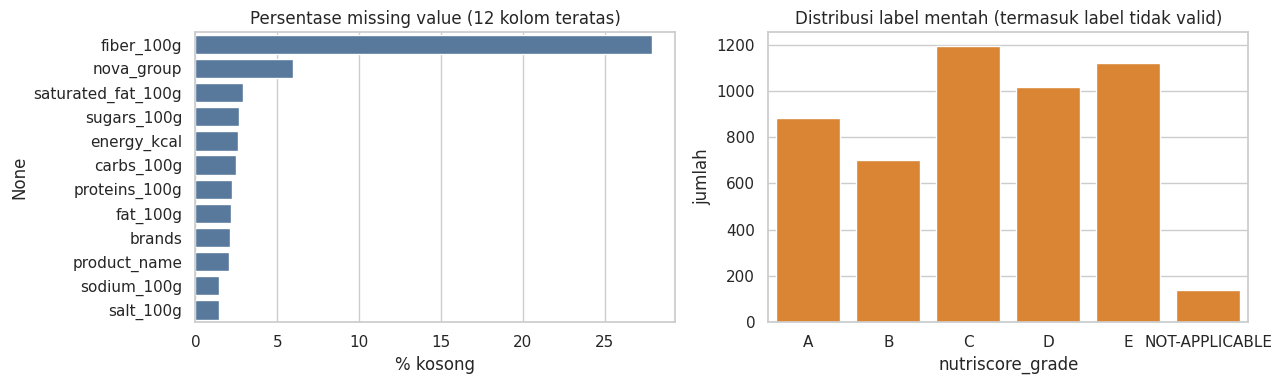

In [5]:
audit = pd.DataFrame({  # tabel ringkasan per kolom
    "tipe": df_raw.dtypes.astype(str),  # tipe data
    "missing": df_raw.isna().sum(),  # jumlah nilai kosong
    "missing_%": (df_raw.isna().mean() * 100).round(2),  # persentase kosong
    "n_unik": df_raw.nunique(),  # jumlah nilai unik
})  # akhir tabel audit
display(audit.sort_values("missing_%", ascending=False))  # urutkan dari yang paling kosong

print("Baris duplikat penuh      :", df_raw.duplicated().sum())  # duplikat persis
print("Distribusi label mentah   :")  # judul
print(df_raw["nutriscore_grade"].astype(str).str.strip().str.upper().value_counts(dropna=False).to_string())  # sebaran label termasuk yang tidak valid

nut = nu.NUTRIENT_COLS  # kolom gizi
impossible = {  # hitung nilai mustahil per aturan
    "gram > 100 per 100 g": int((df_raw[nut[1:]].apply(pd.to_numeric, errors="coerce") > 100).sum().sum()),  # kolom gram >100
    "energi > 900 kcal": int((pd.to_numeric(df_raw["energy_kcal"], errors="coerce") > 900).sum()),  # energi mustahil
    "lemak jenuh > lemak total": int((df_raw["saturated_fat_100g"] > df_raw["fat_100g"]).sum()),  # lemak jenuh melebihi total
    "gula > karbohidrat": int((df_raw["sugars_100g"] > df_raw["carbs_100g"]).sum()),  # gula melebihi karbohidrat
}  # akhir kamus
print("\nNilai gizi mustahil secara fisik:")  # judul
for k, v in impossible.items():  # cetak tiap aturan
    print(f"  - {k}: {v}")  # jumlah pelanggaran
print("\nNilai maksimum serat (g/100 g):", df_raw["fiber_100g"].max())  # contoh outlier ekstrem

fig, ax = plt.subplots(1, 2, figsize=(13, 4))  # dua panel grafik
miss = (df_raw.isna().mean() * 100).sort_values(ascending=False).head(12)  # 12 kolom paling kosong
sns.barplot(x=miss.values, y=miss.index, ax=ax[0], color="#4C78A8")  # bar missing value
ax[0].set_title("Persentase missing value (12 kolom teratas)")  # judul panel 1
ax[0].set_xlabel("% kosong")  # label sumbu x
order = ["A", "B", "C", "D", "E", "NOT-APPLICABLE"]  # urutan label
lbl = df_raw["nutriscore_grade"].astype(str).str.strip().str.upper().value_counts().reindex(order).fillna(0)  # hitung label
sns.barplot(x=lbl.index, y=lbl.values, ax=ax[1], color="#F58518")  # bar distribusi label
ax[1].set_title("Distribusi label mentah (termasuk label tidak valid)")  # judul panel 2
ax[1].set_ylabel("jumlah")  # label sumbu y
plt.tight_layout()  # rapikan tata letak
plt.show()  # tampilkan grafik

### Interpretasi output
Audit menunjukkan bahwa `fiber_100g` memiliki missing value tertinggi, yaitu sekitar 27,91%. Terdapat 480 duplikat penuh dan 137 label `NOT-APPLICABLE` yang tidak termasuk target A–E. Nilai maksimum serat yang sangat besar (sekitar 6,11 × 10¹² g/100 g) jelas tidak masuk akal. Temuan ini menjadi dasar untuk menghapus target tidak valid dan duplikat, serta mengubah nilai gizi yang mustahil menjadi missing value.

## 4. Data Cleaning dengan *Decision Log*

**Tujuan:** menyiapkan data yang layak untuk proses klasifikasi sekaligus mencatat setiap perubahan.

**Keputusan yang digunakan:**
- Baris dengan target di luar A–E tidak dapat dipakai untuk supervised classification, sehingga dikeluarkan.
- Duplikat penuh dihapus agar catatan yang sama tidak dihitung berulang.
- Nilai gizi yang tidak mungkin dijadikan `NaN`, bukan langsung menghapus seluruh baris.
- Baris tanpa satu pun informasi gizi dihapus karena tidak memiliki masukan nutrisi untuk dipelajari.

**Mengapa dilakukan:** setiap keputusan pembersihan dapat ditelusuri dan jumlah data yang berubah tetap terlihat.

**Output yang diharapkan:** `decision_log` dan dataset bersih yang dipakai pada tahap pemodelan.

In [6]:
log = [["Normalisasi tipe data", df_raw.shape[1], "-", "Kolom gizi/NOVA dijadikan numerik, alergen dijadikan 0/1 (database menyimpan semuanya sebagai teks)"]]  # daftar catatan keputusan pembersihan
df = df_raw.copy()  # salin data mentah
n0 = len(df)  # jumlah baris awal

for col in ["nutriscore_grade", "ecoscore_grade", "food_type", "product_name", "brands", "categories"]:  # kolom teks
    df[col] = df[col].astype("string").str.strip()  # hapus spasi berlebih
df["nutriscore_grade"] = df["nutriscore_grade"].str.upper()  # samakan huruf kapital label
df["ecoscore_grade"] = df["ecoscore_grade"].str.upper()  # samakan huruf kapital ecoscore
log.append(["Standardisasi teks", "kolom teks", "-", "Spasi/huruf kapital diseragamkan agar kategori tidak terpecah"])  # catat

invalid = ~df["nutriscore_grade"].isin(GRADES)  # label di luar A-E
log.append(["Buang label tidak valid", int(invalid.sum()), f"{invalid.sum()} baris", "Target harus A-E agar bisa dievaluasi"])  # catat
df = df[~invalid].copy()  # buang baris label tidak valid

dup = df.duplicated()  # duplikat penuh
log.append(["Buang duplikat penuh", int(dup.sum()), f"{dup.sum()} baris", "Duplikat menggelembungkan skor evaluasi"])  # catat
df = df.drop_duplicates().copy()  # buang duplikat

before = df[nu.NUTRIENT_COLS].isna().sum().sum()  # NaN gizi sebelum pembersihan
df_clean_vals = nu.clean_nutrients(df)  # ubah nilai mustahil menjadi NaN
after = df_clean_vals[nu.NUTRIENT_COLS].isna().sum().sum()  # NaN gizi sesudah
log.append(["Nilai gizi mustahil -> NaN", int(after - before), f"{after - before} sel", "Aturan fisik: <=100 g/100 g, energi <=900 kcal, lemak jenuh <= lemak, gula <= karbohidrat"])  # catat
df = df_clean_vals  # pakai data yang sudah dibersihkan

no_info = df[nu.NUTRIENT_COLS].isna().all(axis=1)  # baris tanpa data gizi sama sekali
log.append(["Buang baris tanpa data gizi", int(no_info.sum()), f"{no_info.sum()} baris", "Tidak ada sinyal untuk diprediksi"])  # catat
df = df[~no_info].copy()  # buang baris tersebut

df["nova_group"] = pd.to_numeric(df["nova_group"], errors="coerce")  # NOVA numerik (NaN bila kosong)
df["ecoscore_grade"] = df["ecoscore_grade"].replace({"UNKNOWN": pd.NA, "NOT-APPLICABLE": pd.NA})  # ecoscore tidak valid -> kosong
log.append(["Ecoscore UNKNOWN/NOT-APPLICABLE -> NaN", int(df["ecoscore_grade"].isna().sum()), "-", "Dipakai hanya pada skenario ablasi, bukan model utama"])  # catat

df = df.reset_index(drop=True)  # rapikan indeks
y = df["nutriscore_grade"].map(GRADE_TO_INT).astype(int).to_numpy()  # target ordinal 0-4
groups = (df["product_name"].fillna("na").str.lower() + "|" + df["brands"].fillna("na").str.lower()).to_numpy()  # kunci grup produk-merek
log.append(["Hasil akhir", len(df), f"dari {n0:,} -> {len(df):,} baris", f"{len(np.unique(groups)):,} grup produk-merek unik"])  # catat

decision_log = pd.DataFrame(log, columns=["Langkah", "Jumlah terdampak", "Keterangan", "Alasan"])  # tabel log
display(decision_log)  # tampilkan log
decision_log.to_csv(f"{OUT_DIR}/decision_log.csv", index=False)  # simpan log

,Langkah,Jumlah terdampak,Keterangan,Alasan
0,Normalisasi tipe data,22,-,"Kolom gizi/NOVA dijadikan numerik, alergen dij..."
1,Standardisasi teks,kolom teks,-,Spasi/huruf kapital diseragamkan agar kategori...
2,Buang label tidak valid,137,137 baris,Target harus A-E agar bisa dievaluasi
3,Buang duplikat penuh,478,478 baris,Duplikat menggelembungkan skor evaluasi
4,Nilai gizi mustahil -> NaN,33,33 sel,"Aturan fisik: <=100 g/100 g, energi <=900 kcal..."
5,Buang baris tanpa data gizi,32,32 baris,Tidak ada sinyal untuk diprediksi
6,Ecoscore UNKNOWN/NOT-APPLICABLE -> NaN,789,-,"Dipakai hanya pada skenario ablasi, bukan mode..."
7,Hasil akhir,4405,"dari 5,052 -> 4,405 baris","4,237 grup produk-merek unik"


### Interpretasi output
Setelah cleaning, tersisa 4.405 baris dari 5.052 baris awal dan 4.237 grup produk-merek unik. Sebanyak 137 baris dengan label di luar A–E dikeluarkan, lalu 478 duplikat penuh dihapus setelah penyaringan label. Nilai gizi yang melanggar aturan diubah menjadi `NaN`, sedangkan 32 baris tanpa informasi gizi sama sekali dikeluarkan. `decision_log` membuat perubahan tersebut dapat diperiksa, bukan hanya menghasilkan dataset bersih tanpa catatan.

## 5. Rekayasa Fitur Berbasis Informasi Nutrisi

**Tujuan:** membuat fitur tambahan yang membantu model membaca komposisi nutrisi dan kategori produk, bukan hanya melihat nilai mentah.

| Kelompok fitur | Contoh | Alasan |
|---|---|---|
| Nutrisi mentah | energi, gula, lemak, protein | Memuat informasi dasar per 100 g |
| Rasio | gula/karbohidrat, lemak jenuh/lemak | Menunjukkan komposisi relatif |
| Poin pendekatan | poin energi, gula, natrium, dan lainnya | Memberi ringkasan berbasis aturan sederhana |
| Kategori produk | minuman, keju, camilan, kategori utama | Konteks produk dapat memengaruhi pola label |
| Alergen | gluten, susu, kacang, dan lainnya | Informasi tambahan pada produk |

**Mengapa dilakukan:** dua produk dengan angka nutrisi tertentu dapat memiliki konteks kategori yang berbeda. Fitur turunan membantu model menangkap pola tersebut.

**Catatan:** `nutri_points` adalah fitur pendekatan yang disusun untuk eksperimen. Perhitungannya tidak memasukkan seluruh komponen dan aturan resmi Nutri-Score. `nova_group` dan `ecoscore_grade` tidak dimasukkan ke model utama karena bukan komponen nutrisi yang sedang diprediksi; keduanya hanya diperiksa pada studi ablasi.

`food_type` tidak digunakan sebagai fitur karena audit menunjukkan hanya satu nilai unik, sehingga tidak membantu membedakan produk.

In [7]:
FEATURES_NUM = nu.NUTRIENT_COLS + nu.ENGINEERED_NUM + nu.POINT_NUM + nu.CATEGORY_FLAGS + nu.ALLERGEN_COLS  # fitur numerik model utama
FEATURES_CAT = nu.CATEGORY_CAT  # fitur kategorikal model utama
X = df[nu.RAW_INPUT_COLS + ["nova_group", "ecoscore_grade"]].copy()  # data mentah (nova/eco hanya untuk ablasi)
X_feat = nu.prepare_features(X)  # hitung fitur turunan (hanya untuk EDA)
print("Jumlah fitur model utama:", len(FEATURES_NUM) + len(FEATURES_CAT))  # ringkasan
print("Kategori utama teratas:")  # judul
print(X_feat["main_category"].value_counts().head(8).to_string())  # kategori utama terbanyak
X_feat[["energy_kcal", "sugars_100g", "nutri_points", "is_beverage"]].head()  # contoh fitur turunan

Jumlah fitur model utama: 38
Kategori utama teratas:
main_category
en:plant-based-foods-and-beverages         1780
en:snacks                                   818
en:dairies                                  586
en:beverages-and-beverages-preparations     427
en:condiments                               262
en:breakfasts                                98
en:seafood                                   86
en:meats-and-their-products                  64


,energy_kcal,sugars_100g,nutri_points,is_beverage
0,0.0,1.4,0.0,1
1,NaN,NaN,NaN,1
2,NaN,NaN,NaN,1
3,0.0,0.0,0.0,1
4,45.0,0.0,-1.0,0


### Interpretasi output
Model menggunakan 38 fitur hasil rekayasa: 9 fitur nutrisi, 4 fitur rasio/indikator missing, 9 fitur poin pendekatan, 9 flag kategori, 6 indikator alergen, dan 1 kategori utama. Kategori `plant-based-foods-and-beverages` paling banyak muncul (1.780 produk), disusul snacks (818) dan dairies (586). Komposisi ini penting karena kinerja model nantinya dapat berbeda menurut kategori produk.

## 6. Exploratory Data Analysis (EDA) dan Uji Statistik

**Tujuan:** melihat apakah kandungan nutrisi menunjukkan pola yang berbeda pada tiap grade A–E.

**Metode yang digunakan:**
- Distribusi target untuk melihat proporsi setiap grade setelah cleaning.
- *Kruskal–Wallis* untuk menguji apakah distribusi suatu fitur berbeda di antara lima kelompok grade. Metode non-parametrik ini dipilih karena beberapa fitur nutrisi memiliki sebaran miring dan pencilan.
- Korelasi *Spearman* untuk melihat arah dan kekuatan hubungan monotonik dengan grade yang memiliki urutan.

**Mengapa dilakukan:** EDA membantu memahami data sebelum model dilatih dan memberi petunjuk fitur mana yang perlu diperhatikan.

**Output yang diharapkan:** grafik distribusi kelas, perbandingan poin pendekatan per grade, tabel statistik, dan heatmap korelasi. Hasil statistik menunjukkan hubungan pada data, bukan sebab-akibat.

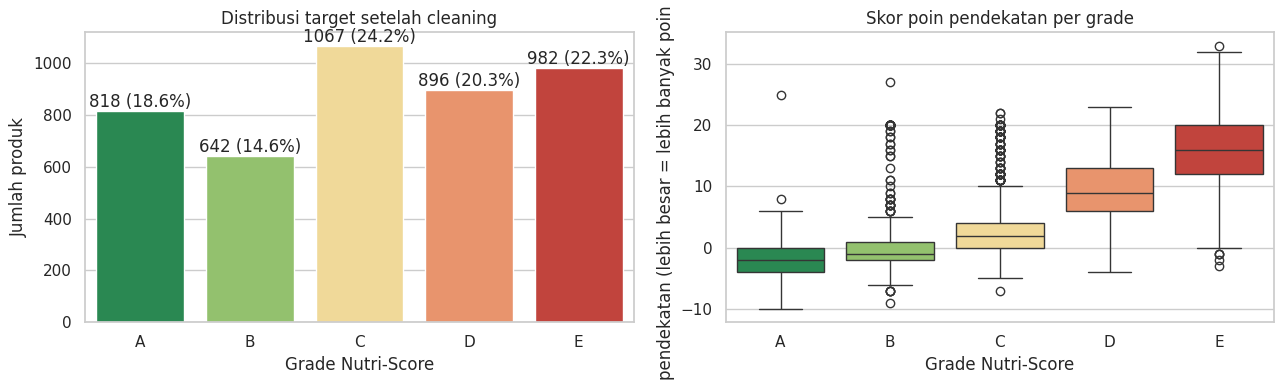

,fitur,n,H_Kruskal,p_value,epsilon_sq,spearman_rho,spearman_p,p_adj_bh
9,nutri_points,4291,2641.8672,0.0,0.6155,0.7832,0.0,0.0
4,sugars_100g,4332,919.6949,0.0,0.2116,0.4401,0.0,0.0
2,saturated_fat_100g,4336,863.0781,0.0,0.1984,0.4445,0.0,0.0
0,energy_kcal,4344,648.9539,0.0,0.1486,0.3792,0.0,0.0
1,fat_100g,4360,565.0271,0.0,0.1288,0.3571,0.0,0.0
8,sodium_100g,4400,359.3129,0.0,0.0808,0.2215,0.0,0.0
7,salt_100g,4399,359.1175,0.0,0.0808,0.2211,0.0,0.0
5,fiber_100g,3284,178.6831,0.0,0.0533,-0.1873,0.0,0.0
6,proteins_100g,4360,225.1015,0.0,0.0508,-0.1809,0.0,0.0
3,carbs_100g,4346,214.5413,0.0,0.0485,0.2003,0.0,0.0


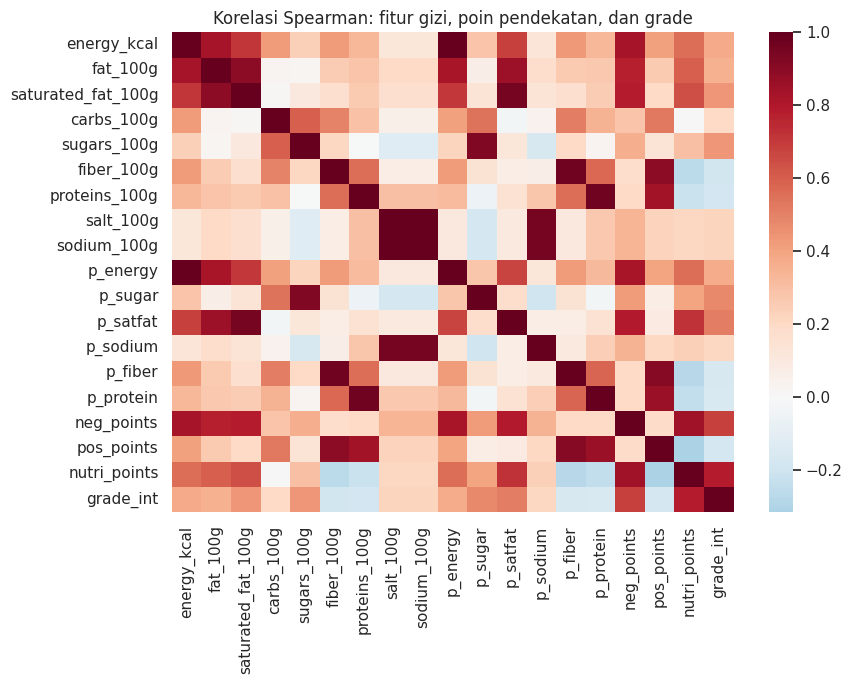

In [8]:
eda = X_feat.copy()
eda["grade"] = pd.Categorical(
    df["nutriscore_grade"], categories=GRADES, ordered=True
)
eda["grade_int"] = y

# A. Distribusi grade dan skor poin pendekatan
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cnt = eda["grade"].value_counts().reindex(GRADES)
sns.barplot(
    x=cnt.index, y=cnt.values, ax=ax[0],
    palette=["#1a9850", "#91cf60", "#fee08b", "#fc8d59", "#d73027"]
)
for i, v in enumerate(cnt.values):
    ax[0].text(i, v, f"{v} ({v / cnt.sum():.1%})", ha="center", va="bottom")
ax[0].set_title("Distribusi target setelah cleaning")
ax[0].set_xlabel("Grade Nutri-Score")
ax[0].set_ylabel("Jumlah produk")

sns.boxplot(
    data=eda, x="grade", y="nutri_points", ax=ax[1],
    palette=["#1a9850", "#91cf60", "#fee08b", "#fc8d59", "#d73027"]
)
ax[1].set_title("Skor poin pendekatan per grade")
ax[1].set_xlabel("Grade Nutri-Score")
ax[1].set_ylabel("Poin pendekatan (lebih besar = lebih banyak poin negatif)")
plt.tight_layout()
plt.show()

# B. Uji Kruskal-Wallis, ukuran efek, dan korelasi Spearman
rows = []
for col in nu.NUTRIENT_COLS + ["nutri_points"]:
    sub = eda[[col, "grade_int"]].dropna()
    groups_k = [
        sub.loc[sub["grade_int"] == k, col].values
        for k in range(5)
    ]

    h, p = stats.kruskal(*groups_k)
    rho, rho_p = stats.spearmanr(sub[col], sub["grade_int"])

    # Estimasi epsilon-squared Kruskal-Wallis:
    # (H - k + 1) / (n - k), dengan k = jumlah kelompok.
    n_obs = len(sub)
    k_groups = len(groups_k)
    eps2 = max(0.0, (h - k_groups + 1) / (n_obs - k_groups))

    rows.append([
        col, n_obs, h, p, eps2, rho, rho_p
    ])

tests = pd.DataFrame(
    rows,
    columns=[
        "fitur", "n", "H_Kruskal", "p_value",
        "epsilon_sq", "spearman_rho", "spearman_p"
    ]
)

# Koreksi Benjamini-Hochberg untuk p-value Kruskal-Wallis.
def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)
    order = np.argsort(p_values)
    ranked = p_values[order] * m / np.arange(1, m + 1)
    adjusted_sorted = np.minimum.accumulate(ranked[::-1])[::-1]
    adjusted = np.empty(m, dtype=float)
    adjusted[order] = np.clip(adjusted_sorted, 0, 1)
    return adjusted

tests["p_adj_bh"] = benjamini_hochberg(tests["p_value"].values)

display(
    tests.sort_values("epsilon_sq", ascending=False).round(4)
)

# C. Korelasi Spearman antarfitur dan grade ordinal
corr = eda[
    nu.NUTRIENT_COLS + nu.POINT_NUM + ["grade_int"]
].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=False)
plt.title("Korelasi Spearman: fitur gizi, poin pendekatan, dan grade")
plt.tight_layout()
plt.show()


### Interpretasi output
Setelah cleaning, distribusi target terdiri dari A=818, B=642, C=1.067, D=896, dan E=982 produk. Kelas B paling sedikit, tetapi tidak terlalu jauh dari kelas lain. Pada tabel statistik, `nutri_points` memiliki hubungan paling kuat dengan grade (epsilon-squared sekitar 0,616 dan Spearman rho 0,783). Gula dan lemak jenuh juga menunjukkan hubungan positif sedang. Temuan ini mendukung pemakaian fitur nutrisi, tetapi hubungan kuat pada `nutri_points` perlu dibaca hati-hati karena fitur tersebut memang dibentuk dari komponen nutrisi yang berkaitan dengan target.

**Cara membaca tabel statistik:** `epsilon_sq` adalah ukuran efek, sedangkan `spearman_rho` menunjukkan arah dan kekuatan hubungan monotonik. Nilai `p_adj_bh` merupakan p-value yang sudah dikoreksi dengan metode Benjamini–Hochberg karena beberapa fitur diuji sekaligus.

Nilai `nutri_points` yang kuat terhadap grade memang diharapkan karena fitur ini dibangun dari komponen nutrisi yang juga berkaitan dengan penentuan grade. Karena itu, hasil ini dibaca sebagai sinyal yang masuk akal, bukan bukti bahwa fitur tersebut merupakan informasi independen atau bahwa model pasti akan bekerja baik pada produk baru.

## 7. Pembagian Data (*Group-Aware Split*)

**Tujuan:** memisahkan data latih dan data uji dengan menjaga agar kombinasi nama produk dan merek yang sama tidak muncul pada kedua bagian.

**Mengapa dilakukan:** satu produk dapat memiliki beberapa varian rasa atau kemasan. Jika varian yang sangat mirip tersebar di data latih dan data uji, model dapat terlihat lebih baik karena sudah melihat produk yang hampir sama.

`StratifiedGroupKFold` dipakai untuk menjaga proporsi kelas sekaligus mempertahankan grup. Satu fold dipilih sebagai data uji sekitar 20%, sedangkan empat fold lainnya menjadi data latih.

**Output yang diharapkan:** ukuran train/test, jumlah grup yang beririsan (harus 0), dan perbandingan proporsi kelas.

In [9]:
from sklearn.model_selection import StratifiedGroupKFold  # pembagi data berkelompok dan berstrata
X_model = X[nu.RAW_INPUT_COLS].copy()  # kolom mentah yang dipakai model final
X["ecoscore_grade"] = X["ecoscore_grade"].astype(object).where(X["ecoscore_grade"].notna(), np.nan)  # ubah pd.NA agar kompatibel dengan imputer
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)  # 5 lipatan -> 1 lipatan = 20% uji
train_idx, test_idx = next(splitter.split(X_model, y, groups))  # ambil lipatan pertama sebagai data uji
X_train, X_test = X_model.iloc[train_idx], X_model.iloc[test_idx]  # fitur train/test
y_train, y_test = y[train_idx], y[test_idx]  # target train/test
g_train, g_test = groups[train_idx], groups[test_idx]  # grup train/test
overlap = set(g_train) & set(g_test)  # irisan grup (harus kosong)
print(f"Train: {len(X_train):,} baris | Test: {len(X_test):,} baris")  # ukuran data
print(f"Grup train: {len(np.unique(g_train)):,} | Grup test: {len(np.unique(g_test)):,} | Grup beririsan: {len(overlap)}")  # verifikasi grup
prop = pd.DataFrame({"train_%": np.bincount(y_train) / len(y_train) * 100, "test_%": np.bincount(y_test) / len(y_test) * 100}, index=GRADES).round(1)  # proporsi kelas
display(prop)  # tampilkan kesamaan proporsi kelas
assert len(overlap) == 0, "Ada grup produk yang bocor antara train dan test!"  # hentikan bila ada kebocoran

Train: 3,525 baris | Test: 880 baris
Grup train: 3,388 | Grup test: 849 | Grup beririsan: 0


,train_%,test_%
A,18.8,17.6
B,14.5,14.8
C,24.3,24.0
D,20.3,20.5
E,22.1,23.2


### Interpretasi output
Pembagian menghasilkan 3.524 baris untuk data latih dan 881 baris untuk data uji. Jumlah grup yang beririsan harus 0; ini menunjukkan kombinasi produk-merek yang sama tidak masuk ke dua bagian sekaligus. Proporsi grade A–E pada train dan test juga hampir sama. Dengan demikian, pengujian lebih mendekati kondisi memprediksi grup produk yang belum dilihat, bukan sekadar varian produk yang mirip.

## 8. Pipeline Pra-pemrosesan

**Tujuan:** menggabungkan rekayasa fitur, imputasi, encoding kategori, scaling jika dibutuhkan, dan model dalam satu alur.

**Mengapa dilakukan:** pada cross-validation, setiap fold harus mempelajari median imputasi, kategori encoding, dan scaling hanya dari bagian latih fold tersebut. Jika seluruh data diproses sebelum split, informasi dari validasi dapat ikut memengaruhi preprocessing.

**Output yang diharapkan:** pipeline dapat dilatih dan jumlah fitur hasil preprocessing dapat diperiksa. Scaling hanya diterapkan pada model yang sensitif terhadap skala, seperti Logistic Regression dan KNN.

In [10]:
from sklearn.pipeline import Pipeline  # perangkai langkah pemrosesan
from sklearn.compose import ColumnTransformer  # transformasi per kelompok kolom
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler  # transformer dasar
from sklearn.impute import SimpleImputer  # pengisi nilai kosong


def build_pipeline(model, num_cols, cat_cols, scale=False):  # pabrik pipeline
    num_steps = [("imputer", SimpleImputer(strategy="median"))]  # imputasi median untuk numerik
    if scale:  # bila model sensitif skala
        num_steps.append(("scaler", StandardScaler()))  # standardisasi
    transformers = [("num", Pipeline(num_steps), num_cols)]  # blok numerik
    if cat_cols:  # bila ada kolom kategorikal
        cat_pipe = Pipeline([  # blok kategorikal
            ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),  # isi kosong dengan 'missing'
            ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False)),  # one-hot, kategori jarang digabung
        ])  # akhir blok kategorikal
        transformers.append(("cat", cat_pipe, cat_cols))  # tambahkan blok
    return Pipeline([  # pipeline lengkap
        ("features", FunctionTransformer(nu.prepare_features, validate=False)),  # rekayasa fitur baris-per-baris
        ("prep", ColumnTransformer(transformers)),  # pra-pemrosesan per kelompok kolom
        ("model", model),  # estimator
    ])  # akhir pipeline


from sklearn.ensemble import HistGradientBoostingClassifier  # model boosting untuk contoh
pipe_demo = build_pipeline(HistGradientBoostingClassifier(random_state=SEED), FEATURES_NUM, FEATURES_CAT)  # contoh pipeline
pipe_demo.fit(X_train, y_train)  # latih contoh untuk memastikan pipeline berjalan
n_out = pipe_demo.named_steps["prep"].transform(pipe_demo.named_steps["features"].transform(X_train.head(5))).shape[1]  # jumlah fitur keluaran
print(f"Pipeline OK. Fitur setelah pra-pemrosesan: {n_out}")  # konfirmasi

Pipeline OK. Fitur setelah pra-pemrosesan: 48


### Interpretasi output
Pesan `Pipeline OK` menunjukkan rangkaian rekayasa fitur, imputasi, encoding, dan model dapat dilatih. Lima sampel menghasilkan 49 kolom setelah preprocessing. Jumlah ini dapat berbeda dari 38 fitur awal karena kategori utama diubah menjadi beberapa kolom one-hot. Yang penting, transformer yang mempelajari nilai median, kategori, atau skala tetap berada di dalam pipeline sehingga dipasang ulang pada setiap fold training.

## 9. Baseline dan Perbandingan Model dengan Cross-Validation

**Tujuan:** membandingkan model sederhana dan beberapa algoritma ML sebelum melakukan tuning.

**Model pembanding:** Dummy, Logistic Regression, KNN, Decision Tree, Random Forest, Extra Trees, dan HistGradientBoosting. Baseline rumus poin pendekatan juga dihitung.

**Mengapa dilakukan:** skor model perlu dibandingkan dengan titik awal yang sederhana. Tanpa baseline, nilai accuracy atau F1 sulit dinilai apakah benar-benar memberi peningkatan.

**Metrik:** accuracy, macro-F1, balanced accuracy, dan Quadratic Weighted Kappa (QWK). Macro-F1 memberi bobot sama pada setiap kelas, sedangkan QWK memperhitungkan urutan grade sehingga kesalahan A ke E lebih berat daripada A ke B.

**Catatan evaluasi:** baseline rule-based akan dihitung pada fold validasi yang sama dengan model ML agar perbandingannya adil.

Dummy (kelas mayoritas)    macro-F1 = 0.078 +/- 0.002
Logistic Regression        macro-F1 = 0.677 +/- 0.019
KNN (k=15)                 macro-F1 = 0.653 +/- 0.017
Decision Tree              macro-F1 = 0.697 +/- 0.021
Random Forest              macro-F1 = 0.822 +/- 0.016
Extra Trees                macro-F1 = 0.801 +/- 0.017
HistGradientBoosting       macro-F1 = 0.819 +/- 0.018


,model,accuracy_mean,f1_macro_mean,f1_macro_std,balanced_accuracy_mean,qwk_mean
0,Random Forest,0.830,0.822,0.016,0.820,0.932
1,HistGradientBoosting,0.826,0.819,0.018,0.817,0.932
2,Extra Trees,0.810,0.801,0.017,0.800,0.926
3,Decision Tree,0.703,0.697,0.021,0.700,0.854
4,Logistic Regression,0.680,0.677,0.019,0.681,0.870
5,KNN (k=15),0.665,0.653,0.017,0.655,0.837
6,Rule-based (poin pendekatan),0.390,0.387,0.017,0.406,0.668
7,Dummy (kelas mayoritas),0.243,0.078,0.002,0.200,0.000


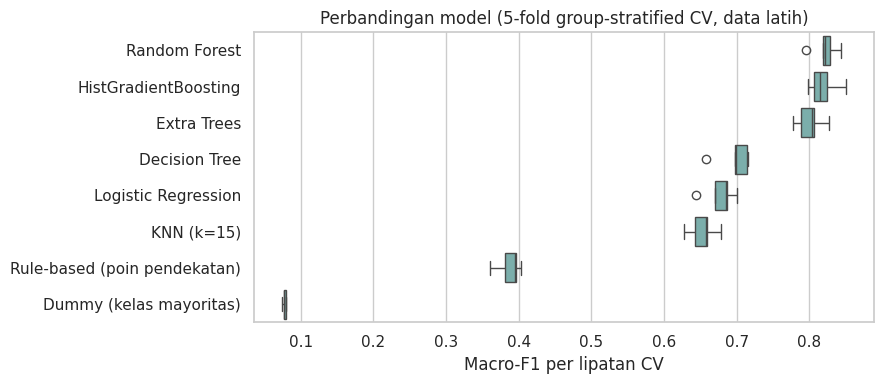

In [11]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    make_scorer, cohen_kappa_score, accuracy_score, f1_score,
    balanced_accuracy_score, mean_absolute_error
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

SCORING = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "qwk": make_scorer(cohen_kappa_score, weights="quadratic"),
}
cv5 = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=SEED
)


def run_cv(name, pipe):
    res = cross_validate(
        pipe, X_train, y_train,
        groups=g_train, cv=cv5, scoring=SCORING, n_jobs=-1
    )
    row = {"model": name}
    for metric in SCORING:
        row[f"{metric}_mean"] = res[f"test_{metric}"].mean()
        row[f"{metric}_std"] = res[f"test_{metric}"].std()
    return row, res["test_f1_macro"]


candidates = {
    "Dummy (kelas mayoritas)": (
        DummyClassifier(strategy="most_frequent"), False
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, class_weight="balanced"), True
    ),
    "KNN (k=15)": (KNeighborsClassifier(n_neighbors=15), True),
    "Decision Tree": (
        DecisionTreeClassifier(
            max_depth=8, class_weight="balanced", random_state=SEED
        ), False
    ),
    "Random Forest": (
        RandomForestClassifier(
            n_estimators=300, class_weight="balanced",
            n_jobs=-1, random_state=SEED
        ), False
    ),
    "Extra Trees": (
        ExtraTreesClassifier(
            n_estimators=300, class_weight="balanced",
            n_jobs=-1, random_state=SEED
        ), False
    ),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(random_state=SEED), False
    ),
}

rows, fold_scores = [], {}

for name, (estimator, scale) in candidates.items():
    result, fold_f1 = run_cv(
        name,
        build_pipeline(
            estimator, FEATURES_NUM, FEATURES_CAT, scale=scale
        )
    )
    rows.append(result)
    fold_scores[name] = fold_f1
    print(
        f"{name:26s} macro-F1 = "
        f"{result['f1_macro_mean']:.3f} +/- {result['f1_macro_std']:.3f}"
    )

# Baseline rule-based dihitung pada fold validasi yang sama.
# Rumus ini tidak dilatih; hanya menerapkan aturan pendekatan pada fold validasi.
rule_fold_rows = []
rule_name = "Rule-based (poin pendekatan)"

for train_fold_idx, valid_fold_idx in cv5.split(
    X_train, y_train, groups=g_train
):
    X_valid_fold = X_train.iloc[valid_fold_idx]
    y_valid_fold = y_train[valid_fold_idx]

    rule_pred_fold = nu.rule_based_grade(
        nu.prepare_features(X_valid_fold)
    )

    rule_fold_rows.append({
        "accuracy": accuracy_score(y_valid_fold, rule_pred_fold),
        "f1_macro": f1_score(
            y_valid_fold, rule_pred_fold, average="macro"
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_valid_fold, rule_pred_fold
        ),
        "qwk": cohen_kappa_score(
            y_valid_fold, rule_pred_fold, weights="quadratic"
        ),
    })

rule_fold_df = pd.DataFrame(rule_fold_rows)
rule_row = {"model": rule_name}
for metric in ["accuracy", "f1_macro", "balanced_accuracy", "qwk"]:
    rule_row[f"{metric}_mean"] = rule_fold_df[metric].mean()
    rule_row[f"{metric}_std"] = rule_fold_df[metric].std()

rows.append(rule_row)
fold_scores[rule_name] = rule_fold_df["f1_macro"].to_numpy()

cv_table = (
    pd.DataFrame(rows)
    .sort_values("f1_macro_mean", ascending=False)
    .reset_index(drop=True)
)

display(
    cv_table[
        [
            "model", "accuracy_mean", "f1_macro_mean",
            "f1_macro_std", "balanced_accuracy_mean", "qwk_mean"
        ]
    ].round(3)
)

plt.figure(figsize=(9, 4))
order = [
    model_name for model_name in cv_table["model"]
    if model_name in fold_scores
]
sns.boxplot(
    data=pd.DataFrame({k: fold_scores[k] for k in order}),
    orient="h", color="#72B7B2"
)
plt.xlabel("Macro-F1 per lipatan CV")
plt.title("Perbandingan model (5-fold group-stratified CV, data latih)")
plt.tight_layout()
plt.show()


### Interpretasi output
Pada hasil awal, Random Forest memperoleh macro-F1 CV sekitar 0,826 ± 0,009, diikuti HistGradientBoosting sekitar 0,821 ± 0,018 dan Extra Trees sekitar 0,805 ± 0,010. Dummy hanya sekitar 0,078, sehingga model ML memberi peningkatan yang jelas dibanding tebakan kelas mayoritas. Baseline rule-based sekarang juga dihitung pada fold validasi yang sama, sehingga perbandingan macro-F1 lebih adil. Hasil ini menjadi alasan untuk melakukan tuning pada Random Forest dan HistGradientBoosting, bukan langsung memilih model dari satu kali training.

## 10. Tuning Hyperparameter

**Tujuan:** mencari kombinasi parameter yang lebih sesuai untuk dua model berbasis pohon yang menunjukkan hasil kuat pada tahap perbandingan awal.

`RandomizedSearchCV` mencoba sebagian kombinasi parameter dari ruang pencarian. Proses ini menggunakan 3-fold group-stratified CV di dalam data latih dan macro-F1 sebagai skor utama.

**Mengapa dilakukan:** performa model dapat dipengaruhi oleh jumlah pohon, kedalaman, ukuran daun, dan parameter regularisasi. Tuning membantu memilih konfigurasi berdasarkan validasi, bukan menebak parameter.

**Output yang diharapkan:** parameter terbaik dan skor CV pencarian untuk Random Forest serta HistGradientBoosting. Skor ini belum menjadi hasil akhir pada data uji.

In [12]:
from sklearn.model_selection import RandomizedSearchCV  # pencarian acak hyperparameter
from scipy.stats import loguniform  # distribusi log-uniform untuk learning rate

cv3 = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)  # CV dalam untuk tuning
space_rf = {  # ruang pencarian Random Forest
    "model__n_estimators": [200, 400, 600],  # jumlah pohon
    "model__max_depth": [None, 12, 20, 30],  # kedalaman maksimum
    "model__min_samples_leaf": [1, 2, 4],  # minimum sampel per daun
    "model__max_features": ["sqrt", 0.3, 0.5],  # fitur per split
}  # akhir ruang RF
space_hgb = {  # ruang pencarian HistGradientBoosting
    "model__learning_rate": loguniform(0.02, 0.2),  # kecepatan belajar
    "model__max_iter": [200, 300, 500],  # jumlah iterasi
    "model__max_leaf_nodes": [15, 31, 63],  # jumlah daun maksimum
    "model__min_samples_leaf": [10, 20, 40],  # minimum sampel per daun
    "model__l2_regularization": loguniform(1e-3, 10),  # regularisasi L2
}  # akhir ruang HGB

search_rf = RandomizedSearchCV(build_pipeline(RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=SEED), FEATURES_NUM, FEATURES_CAT),  # pipeline RF
                               space_rf, n_iter=10, scoring="f1_macro", cv=cv3, random_state=SEED, n_jobs=-1, refit=True)  # pengaturan pencarian RF
search_hgb = RandomizedSearchCV(build_pipeline(HistGradientBoostingClassifier(random_state=SEED), FEATURES_NUM, FEATURES_CAT),  # pipeline HGB
                                space_hgb, n_iter=15, scoring="f1_macro", cv=cv3, random_state=SEED, n_jobs=-1, refit=True)  # pengaturan pencarian HGB
search_rf.fit(X_train, y_train, groups=g_train)  # cari parameter RF terbaik
search_hgb.fit(X_train, y_train, groups=g_train)  # cari parameter HGB terbaik
show_params = lambda d: {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in d.items()}  # rapikan tampilan parameter
print("RF  terbaik  :", show_params(search_rf.best_params_), "| F1 =", round(search_rf.best_score_, 4))  # laporan RF
print("HGB terbaik  :", show_params(search_hgb.best_params_), "| F1 =", round(search_hgb.best_score_, 4))  # laporan HGB

RF  terbaik  : {'n_estimators': 600, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': None} | F1 = 0.8162
HGB terbaik  : {'l2_regularization': 0.2802, 'learning_rate': 0.0276, 'max_iter': 500, 'max_leaf_nodes': 31, 'min_samples_leaf': 20} | F1 = 0.8182


### Interpretasi output
Randomized Search menemukan konfigurasi hyperparameter terbaik untuk masing-masing model melalui 3-fold Group CV. HistGradientBoosting memperoleh skor F1-Macro sebesar 0.8182, sedikit lebih tinggi dibandingkan Random Forest yang memperoleh skor 0.8162. Selisih performa kedua model relatif kecil, sehingga belum cukup untuk menyimpulkan bahwa HistGradientBoosting secara signifikan lebih unggul. Kedua model akan dibandingkan kembali pada tahap evaluasi berikutnya menggunakan skema CV yang sama.

## 11. Klasifikasi Ordinal dan Ensemble

**Tujuan:** memeriksa apakah sifat grade yang berurutan dapat dimanfaatkan melalui pendekatan ordinal, dan apakah penggabungan model memberikan peningkatan.

Dua pendekatan tambahan:
1. **Ordinal Frank–Hall:** mengubah masalah menjadi beberapa klasifikasi biner bertingkat, misalnya apakah grade lebih buruk dari A, lebih buruk dari B, dan seterusnya.
2. **Soft voting:** menggabungkan probabilitas Random Forest dan HistGradientBoosting.

**Mengapa dilakukan:** klasifikasi biasa tidak secara eksplisit memanfaatkan urutan kelas A–E. Eksperimen ini memeriksa apakah pendekatan ordinal atau ensemble memberi hasil lebih baik.

**Output yang diharapkan:** perbandingan kandidat pada 5-fold group-stratified CV di data latih. Model dipilih berdasarkan macro-F1 CV, bukan berdasarkan data uji.

In [13]:
from sklearn.base import clone  # menyalin estimator
from sklearn.ensemble import VotingClassifier  # ensemble voting

best_rf = clone(search_rf.best_estimator_.named_steps["model"])  # RF dengan parameter terbaik (belum dilatih)
best_hgb = clone(search_hgb.best_estimator_.named_steps["model"])  # HGB dengan parameter terbaik (belum dilatih)
final_candidates = {  # kandidat final
    "RF (tuned)": build_pipeline(clone(best_rf), FEATURES_NUM, FEATURES_CAT),  # RF tuning
    "HGB (tuned)": build_pipeline(clone(best_hgb), FEATURES_NUM, FEATURES_CAT),  # HGB tuning
    "Ordinal-HGB (tuned)": build_pipeline(nu.OrdinalClassifier(clone(best_hgb)), FEATURES_NUM, FEATURES_CAT),  # model ordinal
    "Voting RF+HGB (soft)": build_pipeline(VotingClassifier([("rf", clone(best_rf)), ("hgb", clone(best_hgb))], voting="soft"), FEATURES_NUM, FEATURES_CAT),  # ensemble
}  # akhir kandidat final

rows2, fold2 = [], {}  # penampung hasil
for name, pipe in final_candidates.items():  # tiap kandidat final
    r, fs = run_cv(name, pipe)  # jalankan CV 5-lipatan
    rows2.append(r)  # simpan baris
    fold2[name] = fs  # simpan skor per lipatan
cv_final = pd.DataFrame(rows2).sort_values("f1_macro_mean", ascending=False).reset_index(drop=True)  # urutkan kandidat
display(cv_final[["model", "accuracy_mean", "f1_macro_mean", "f1_macro_std", "balanced_accuracy_mean", "qwk_mean"]].round(4))  # tampilkan hasil

best_name = cv_final.loc[0, "model"]  # nama pemenang berdasarkan CV
final_pipe = final_candidates[best_name]  # pipeline pemenang
print(f"\nModel final terpilih (berdasarkan CV macro-F1 pada data latih): {best_name}")  # umumkan pemenang

,model,accuracy_mean,f1_macro_mean,f1_macro_std,balanced_accuracy_mean,qwk_mean
0,Ordinal-HGB (tuned),0.8403,0.8337,0.0126,0.8339,0.9405
1,RF (tuned),0.8346,0.8261,0.0127,0.8245,0.9347
2,Voting RF+HGB (soft),0.8315,0.8228,0.0170,0.8216,0.9333
3,HGB (tuned),0.8276,0.8186,0.0179,0.8176,0.9302



Model final terpilih (berdasarkan CV macro-F1 pada data latih): Ordinal-HGB (tuned)


### Interpretasi output
Pada perbandingan kandidat model menggunakan Cross-Validation, Ordinal-HGB (tuned) memperoleh nilai rata-rata macro-F1 tertinggi sebesar 0.8337, diikuti RF (tuned) sebesar 0.8261, Voting RF+HGB (soft) sebesar 0.8228, dan HGB (tuned) sebesar 0.8186. Ordinal-HGB juga memperoleh nilai accuracy, balanced accuracy, dan QWK tertinggi dibandingkan kandidat lainnya. Berdasarkan hasil tersebut, Ordinal-HGB (tuned) dipilih sebagai model final sementara berdasarkan rata-rata macro-F1 pada data latih. Selanjutnya, performanya tetap perlu dievaluasi pada data test yang dipisahkan untuk memperoleh gambaran kemampuan generalisasi model terhadap data yang belum pernah dilihat.

## 12. Evaluasi Akhir pada Data Uji

**Tujuan:** mengukur performa model terpilih pada produk yang grupnya tidak digunakan saat training.

**Mengapa dilakukan:** cross-validation dipakai untuk memilih model, sedangkan data uji memberikan pemeriksaan akhir pada data terpisah. Data uji tidak digunakan untuk tuning atau memilih pemenang.

Selain accuracy, macro-F1, balanced accuracy, dan QWK, notebook menghitung selang kepercayaan 95% dengan *group bootstrap*. Unit resampling adalah grup produk-merek, bukan baris satu per satu, agar ketergantungan antarvarian produk lebih diperhatikan.

**Output yang diharapkan:** metrik keseluruhan, metrik per kelas, confusion matrix, dan perbandingan dengan baseline pada test set yang sama.

Jumlah grup pada test set: 849
Akurasi             : 0.836 (95% group-bootstrap CI 0.814-0.863)
Macro-F1            : 0.833 (95% group-bootstrap CI 0.809-0.859)
Balanced accuracy   : 0.833
QWK                 : 0.938
MAE (langkah grade) : 0.189
Salah <= 1 grade    : 97.6%

              precision    recall  f1-score   support

           A      0.890     0.884     0.887       155
           B      0.729     0.746     0.738       130
           C      0.784     0.773     0.778       211
           D      0.834     0.867     0.850       180
           E      0.924     0.897     0.910       204

    accuracy                          0.836       880
   macro avg      0.832     0.833     0.833       880
weighted avg      0.837     0.836     0.837       880



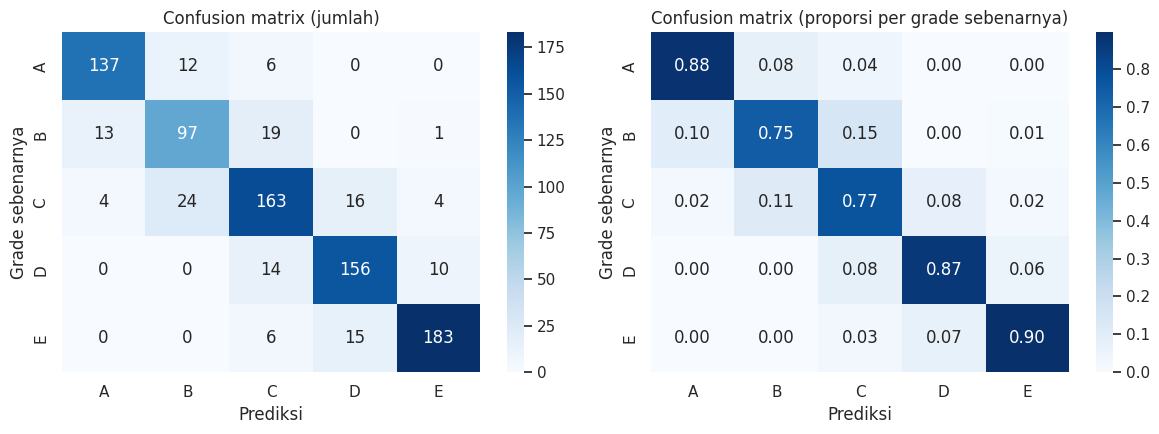

,model,accuracy,macro_f1,qwk
0,Dummy,0.240,0.077,0.000
1,Rule-based (poin pendekatan),0.432,0.427,0.689
2,Ordinal-HGB (tuned) (final),0.836,0.833,0.938


In [14]:
from sklearn.metrics import classification_report, confusion_matrix

# Latih ulang model terpilih pada seluruh data latih, lalu uji sekali pada test set.
final_pipe.fit(X_train, y_train)
pred = final_pipe.predict(X_test)
proba = final_pipe.predict_proba(X_test)

metrics = {
    "accuracy": accuracy_score(y_test, pred),
    "macro_f1": f1_score(y_test, pred, average="macro"),
    "weighted_f1": f1_score(y_test, pred, average="weighted"),
    "balanced_accuracy": balanced_accuracy_score(y_test, pred),
    "qwk": cohen_kappa_score(y_test, pred, weights="quadratic"),
    "mae_grade_steps": mean_absolute_error(y_test, pred),
    "within_1_grade": float((np.abs(y_test - pred) <= 1).mean()),
}

# Group bootstrap: grup produk-merek diambil sebagai unit resampling.
# Ini mengurangi asumsi bahwa beberapa varian dalam grup yang sama sepenuhnya independen.
rng = np.random.default_rng(SEED)
unique_test_groups = np.unique(g_test)
group_to_indices = {
    group: np.flatnonzero(g_test == group)
    for group in unique_test_groups
}

boot_f1, boot_acc = [], []
for _ in range(1000):
    sampled_groups = rng.choice(
        unique_test_groups,
        size=len(unique_test_groups),
        replace=True
    )
    sampled_idx = np.concatenate([
        group_to_indices[group] for group in sampled_groups
    ])

    boot_f1.append(
        f1_score(
            y_test[sampled_idx], pred[sampled_idx], average="macro"
        )
    )
    boot_acc.append(
        accuracy_score(y_test[sampled_idx], pred[sampled_idx])
    )

ci_f1 = np.percentile(boot_f1, [2.5, 97.5])
ci_acc = np.percentile(boot_acc, [2.5, 97.5])

print(f"Jumlah grup pada test set: {len(unique_test_groups):,}")
print(
    f"Akurasi             : {metrics['accuracy']:.3f} "
    f"(95% group-bootstrap CI {ci_acc[0]:.3f}-{ci_acc[1]:.3f})"
)
print(
    f"Macro-F1            : {metrics['macro_f1']:.3f} "
    f"(95% group-bootstrap CI {ci_f1[0]:.3f}-{ci_f1[1]:.3f})"
)
print(f"Balanced accuracy   : {metrics['balanced_accuracy']:.3f}")
print(f"QWK                 : {metrics['qwk']:.3f}")
print(f"MAE (langkah grade) : {metrics['mae_grade_steps']:.3f}")
print(f"Salah <= 1 grade    : {metrics['within_1_grade']:.1%}")
print()
print(
    classification_report(
        y_test, pred, target_names=GRADES, digits=3, zero_division=0
    )
)

cm = confusion_matrix(y_test, pred)
cm_norm = confusion_matrix(y_test, pred, normalize="true")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=GRADES, yticklabels=GRADES, ax=ax[0]
)
ax[0].set_title("Confusion matrix (jumlah)")

sns.heatmap(
    cm_norm, annot=True, fmt=".2f", cmap="Blues",
    xticklabels=GRADES, yticklabels=GRADES, ax=ax[1]
)
ax[1].set_title("Confusion matrix (proporsi per grade sebenarnya)")

for axis in ax:
    axis.set_xlabel("Prediksi")
    axis.set_ylabel("Grade sebenarnya")

plt.tight_layout()
plt.show()

# Semua baseline dan model final dibandingkan pada test set yang sama.
comp = []
dummy_pred = (
    DummyClassifier(strategy="most_frequent")
    .fit(X_train, y_train)
    .predict(X_test)
)
rule_test = nu.rule_based_grade(nu.prepare_features(X_test))

for model_label, prediction in [
    ("Dummy", dummy_pred),
    ("Rule-based (poin pendekatan)", rule_test),
    (f"{best_name} (final)", pred),
]:
    comp.append([
        model_label,
        accuracy_score(y_test, prediction),
        f1_score(y_test, prediction, average="macro"),
        cohen_kappa_score(y_test, prediction, weights="quadratic"),
    ])

display(
    pd.DataFrame(
        comp, columns=["model", "accuracy", "macro_f1", "qwk"]
    ).round(3)
)


### Interpretasi output
Pada test set, Ordinal-HGB (tuned) sebagai model final menghasilkan accuracy sebesar 0.836, macro-F1 sebesar 0.833, balanced accuracy sebesar 0.833, dan QWK sebesar 0.938. Nilai MAE sebesar 0.189 menunjukkan bahwa rata-rata kesalahan prediksi berada di bawah satu tingkat grade. Selain itu, sekitar 97.6% prediksi memiliki selisih maksimal satu tingkat grade dari label sebenarnya. Berdasarkan classification report, kelas B memperoleh F1-score terendah sebesar 0.738, sehingga masih menjadi kelas yang relatif lebih sulit diprediksi. Confusion matrix juga menunjukkan bahwa sebagian kesalahan prediksi terjadi pada grade yang berdekatan, terutama antara kelas B dan C. Hasil perbandingan menunjukkan bahwa Ordinal-HGB mengungguli Dummy dan baseline berbasis aturan pada test set yang sama. Interval bootstrap dihitung pada tingkat grup produk-merek untuk memperhitungkan variasi antarkelompok.

## 13. Studi Ablasi Fitur

**Tujuan:** memeriksa kontribusi kelompok fitur dengan menambahkan fitur secara bertahap, mulai dari nutrisi mentah hingga kategori, alergen, dan informasi NOVA/Ecoscore.

**Mengapa dilakukan:** fitur tambahan tidak selalu meningkatkan model. Studi ablasi membantu melihat apakah fitur rekayasa benar-benar memberi peningkatan atau justru tidak membantu.

**Catatan penting:** semua skenario menggunakan HistGradientBoosting sebagai model pembanding agar perubahan lebih banyak mencerminkan kelompok fitur yang digunakan. Hasil ablasi ini tidak boleh disamakan langsung dengan hasil Random Forest final. Selisih terhadap simpangan baku fold hanya petunjuk variasi, bukan uji signifikansi formal.

**Output yang diharapkan:** tabel dan grafik macro-F1 dari setiap skenario.

,skenario,macro_f1,std,accuracy,qwk
0,S1 Nutrisi mentah,0.7828,0.0210,0.7910,0.9075
1,S2 + Rasio,0.7761,0.0205,0.7856,0.9044
2,S3 + Poin Nutri-Score,0.8064,0.0168,0.8145,0.9133
3,S4 + Kategori produk,0.8200,0.0222,0.8284,0.9328
4,S5 + Alergen,0.8187,0.0181,0.8264,0.9324
5,"S6 + NOVA & Ecoscore (diuji, tidak dipakai)",0.8271,0.0116,0.8358,0.9402


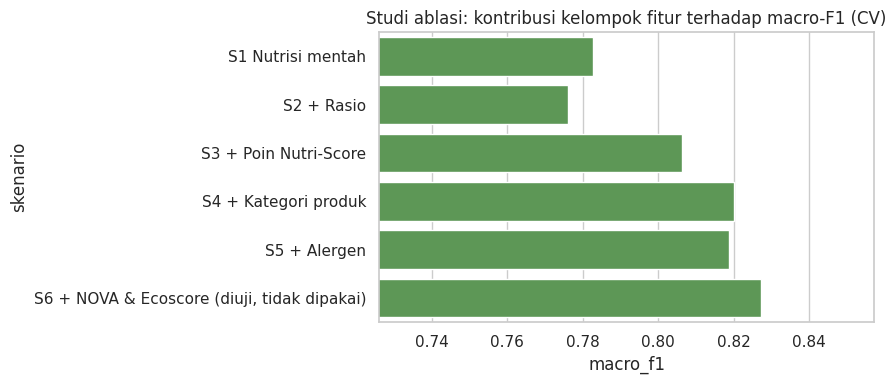

In [15]:
scenarios = {  # skenario ablasi: (kolom numerik, kolom kategorikal)
    "S1 Nutrisi mentah": (nu.NUTRIENT_COLS, []),  # hanya 9 kolom gizi
    "S2 + Rasio": (nu.NUTRIENT_COLS + nu.ENGINEERED_NUM, []),  # tambah rasio
    "S3 + Poin Nutri-Score": (nu.NUTRIENT_COLS + nu.ENGINEERED_NUM + nu.POINT_NUM, []),  # tambah poin domain
    "S4 + Kategori produk": (nu.NUTRIENT_COLS + nu.ENGINEERED_NUM + nu.POINT_NUM + nu.CATEGORY_FLAGS, nu.CATEGORY_CAT),  # tambah kategori
    "S5 + Alergen": (FEATURES_NUM, FEATURES_CAT),  # fitur model utama
    "S6 + NOVA & Ecoscore (diuji, tidak dipakai)": (FEATURES_NUM + ["nova_group"], FEATURES_CAT + ["ecoscore_grade"]),  # skor turunan lain
}  # akhir skenario
X_train_abl = X.iloc[train_idx]  # data latih dengan kolom nova/eco
abl_rows = []  # hasil ablasi
for name, (num_c, cat_c) in scenarios.items():  # tiap skenario
    pipe = build_pipeline(HistGradientBoostingClassifier(random_state=SEED), num_c, cat_c)  # pipeline skenario
    res = cross_validate(pipe, X_train_abl, y_train, groups=g_train, cv=cv5, scoring=SCORING, n_jobs=-1)  # CV
    abl_rows.append([name, res["test_f1_macro"].mean(), res["test_f1_macro"].std(), res["test_accuracy"].mean(), res["test_qwk"].mean()])  # simpan
ablation = pd.DataFrame(abl_rows, columns=["skenario", "macro_f1", "std", "accuracy", "qwk"])  # tabel ablasi
display(ablation.round(4))  # tampilkan tabel

plt.figure(figsize=(9, 4))  # ukuran grafik
sns.barplot(data=ablation, y="skenario", x="macro_f1", color="#54A24B")  # bar macro-F1 per skenario
plt.xlim(max(0, ablation["macro_f1"].min() - 0.05), min(1, ablation["macro_f1"].max() + 0.03))  # zoom sumbu agar beda terlihat
plt.title("Studi ablasi: kontribusi kelompok fitur terhadap macro-F1 (CV)")  # judul
plt.tight_layout()  # rapikan
plt.show()  # tampilkan

### Interpretasi output
Pada eksperimen ablation menggunakan HistGradientBoosting, skenario nutrisi mentah (S1) menghasilkan macro-F1 sebesar 0.7828. Penambahan fitur rasio pada S2 justru menurunkan skor menjadi 0.7761. Setelah fitur poin Nutri-Score ditambahkan pada S3, macro-F1 meningkat menjadi 0.8064. Penambahan kategori produk pada S4 kembali meningkatkan performa menjadi 0.8200, yang merupakan skor tertinggi di antara skenario fitur yang dipertahankan. Sementara itu, penambahan indikator alergen pada S5 sedikit menurunkan macro-F1 menjadi 0.8187. Skenario S6 yang menguji penambahan NOVA dan Ecoscore memperoleh macro-F1 tertinggi sebesar 0.8271, tetapi kedua kelompok fitur tersebut tidak digunakan pada konfigurasi akhir. Hasil ini menunjukkan bahwa poin Nutri-Score dan kategori produk memberikan kontribusi positif terhadap performa model, sedangkan fitur rasio dan alergen belum menunjukkan peningkatan pada eksperimen ini.

**Cara membaca hasil ablasi:** perhatikan perubahan macro-F1 dari satu skenario ke skenario berikutnya, lalu bandingkan dengan variasi skor antar-fold (`std`). Jika perubahan relatif kecil dibanding variasi fold, bukti peningkatannya belum kuat. Namun, `std` bukan standard error dan perbandingan ini bukan uji signifikansi statistik formal.

Apabila penambahan fitur menurunkan skor, hasil tersebut tetap dilaporkan. Tujuan ablasi adalah mengetahui kontribusi fitur, bukan mencari angka yang selalu meningkat.

## 14. Interpretasi Model dengan Permutation Importance

**Tujuan:** mengetahui fitur mentah mana yang paling memengaruhi performa model secara keseluruhan.

Metode ini mengacak satu kolom pada data uji, lalu mengukur seberapa besar macro-F1 menurun. Jika penurunannya besar, model banyak bergantung pada informasi dari kolom tersebut.

**Mengapa dilakukan:** hasil ini membantu menjelaskan fitur yang paling banyak digunakan model saat membedakan grade.

**Batas interpretasi:** permutation importance bersifat global dan tidak menjelaskan alasan satu produk tertentu memperoleh grade tertentu. Nilainya juga dapat dipengaruhi korelasi antarfitur. Hasil ini bukan hubungan sebab-akibat.

,kolom_mentah,penurunan_f1,std
0,sugars_100g,0.2991,0.0087
1,saturated_fat_100g,0.2849,0.0113
2,sodium_100g,0.2216,0.0089
3,energy_kcal,0.2101,0.0135
4,carbs_100g,0.1927,0.0103
5,fat_100g,0.1878,0.0091
6,proteins_100g,0.1620,0.0066
7,fiber_100g,0.1580,0.0075
8,categories,0.0678,0.0055
9,salt_100g,0.0464,0.0035


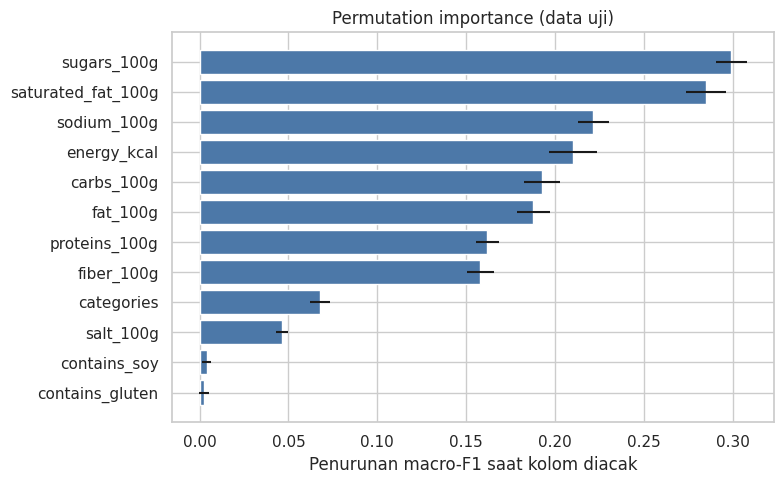

In [16]:
from sklearn.inspection import permutation_importance  # fungsi importance berbasis pengacakan

perm = permutation_importance(final_pipe, X_test, y_test, scoring="f1_macro", n_repeats=10, random_state=SEED, n_jobs=-1)  # hitung importance
imp = pd.DataFrame({"kolom_mentah": X_test.columns, "penurunan_f1": perm.importances_mean, "std": perm.importances_std})  # tabel importance
imp = imp.sort_values("penurunan_f1", ascending=False).reset_index(drop=True)  # urutkan
display(imp.head(12).round(4))  # tampilkan 12 teratas

plt.figure(figsize=(8, 5))  # ukuran grafik
top = imp.head(12).iloc[::-1]  # 12 teratas, dibalik agar terbesar di atas
plt.barh(top["kolom_mentah"], top["penurunan_f1"], xerr=top["std"], color="#4C78A8")  # bar horizontal dengan galat
plt.xlabel("Penurunan macro-F1 saat kolom diacak")  # label sumbu
plt.title("Permutation importance (data uji)")  # judul
plt.tight_layout()  # rapikan
plt.show()  # tampilkan

### Interpretasi output
Permutation importance menempatkan gula (`sugars_100g`), lemak jenuh (`saturated_fat_100g`), dan natrium (`sodium_100g`) sebagai tiga fitur dengan penurunan macro-F1 terbesar ketika diacak. Artinya, model banyak menggunakan informasi dari fitur tersebut saat membedakan grade. Nilai importance yang kecil pada beberapa indikator alergen menunjukkan kontribusi global yang terbatas pada model dan dataset ini. Hasil ini tidak membuktikan sebab-akibat dan tidak menjelaskan kontribusi fitur pada satu produk secara individual.

## 15. Analisis Error

**Tujuan:** melihat kondisi ketika model lebih sering salah, bukan hanya melaporkan skor rata-rata.

Analisis dilakukan pada:
- Akurasi per kategori produk dengan minimal 25 produk uji.
- Perbandingan produk yang memiliki dan tidak memiliki data serat.
- Perbandingan minuman dengan bukan minuman.
- Contoh produk yang salah diprediksi.

**Mengapa dilakukan:** nilai metrik keseluruhan dapat menutupi kelemahan pada kelompok tertentu. Analisis per kelompok membantu menentukan bagian mana yang perlu diperbaiki.

**Output yang diharapkan:** tabel akurasi per segmen dan beberapa contoh kesalahan. Perbedaan akurasi deskriptif tidak otomatis membuktikan penyebab kesalahan.

In [17]:
test_feat = nu.prepare_features(X_test).reset_index(drop=True)  # fitur turunan data uji
err = pd.DataFrame({  # tabel prediksi uji
    "product": df.loc[test_idx, "product_name"].to_numpy(),  # nama produk
    "kategori": test_feat["main_category"].to_numpy(),  # kategori utama
    "benar": y_test, "prediksi": pred,  # label asli dan prediksi
    "fiber_kosong": test_feat["fiber_missing"].to_numpy(),  # penanda serat kosong
    "minuman": test_feat["is_beverage"].to_numpy(),  # penanda minuman
    "skor_poin": test_feat["nutri_points"].to_numpy(),  # skor poin pendekatan
})  # akhir tabel
err["akurat"] = (err["benar"] == err["prediksi"]).astype(int)  # penanda prediksi tepat

by_cat = err.groupby("kategori").agg(n=("akurat", "size"), akurasi=("akurat", "mean")).query("n >= 25").sort_values("akurasi")  # akurasi per kategori (n>=25)
print("Akurasi per kategori produk (minimal 25 produk uji):")  # judul
display(by_cat.round(3))  # tampilkan tabel

print("\nAkurasi berdasarkan ketersediaan data serat:")  # judul
display(err.groupby("fiber_kosong")["akurat"].agg(["size", "mean"]).rename(index={0: "serat tersedia", 1: "serat kosong"}).round(3))  # perbandingan serat
print("\nAkurasi minuman vs bukan minuman:")  # judul
display(err.groupby("minuman")["akurat"].agg(["size", "mean"]).rename(index={0: "bukan minuman", 1: "minuman"}).round(3))  # perbandingan minuman

wrong = err[err["akurat"] == 0].copy()  # produk yang salah
wrong["benar"] = wrong["benar"].map(dict(enumerate(GRADES)))  # ubah angka ke huruf
wrong["prediksi"] = wrong["prediksi"].map(dict(enumerate(GRADES)))  # ubah angka ke huruf
print(f"\nContoh kesalahan (dari {len(wrong)} kesalahan uji):")  # judul
display(wrong.sample(min(10, len(wrong)), random_state=SEED)[["product", "kategori", "benar", "prediksi", "skor_poin", "fiber_kosong"]])  # contoh acak

Akurasi per kategori produk (minimal 25 produk uji):


,n,akurasi
kategori,,
en:beverages-and-beverages-preparations,77,0.688
en:plant-based-foods-and-beverages,332,0.795
en:dairies,130,0.885
en:condiments,63,0.889
en:snacks,179,0.911



Akurasi berdasarkan ketersediaan data serat:


,size,mean
fiber_kosong,,
serat tersedia,651,0.837
serat kosong,229,0.834



Akurasi minuman vs bukan minuman:


,size,mean
minuman,,
bukan minuman,459,0.895
minuman,421,0.772



Contoh kesalahan (dari 144 kesalahan uji):


,product,kategori,benar,prediksi,skor_poin,fiber_kosong
735,Sauce Bourguignonne,en:condiments,D,E,18.0,1
138,Bonbons,en:snacks,C,D,9.0,1
553,Croustillant graines de courge et de tournesol,en:plant-based-foods-and-beverages,C,B,-1.0,0
651,Beurre bio cacahuètes crunchy,en:plant-based-foods-and-beverages,C,B,7.0,0
413,<NA>,en:plant-based-foods-and-beverages,D,C,4.0,0
93,Kefir,en:beverages,B,C,0.0,1
829,Roasted Cashew-Peanut-Mix Honey & Salt,en:plant-based-foods-and-beverages,D,E,11.0,0
457,Chunky chopped tomatoes,en:plant-based-foods-and-beverages,B,A,0.0,0
459,Fruity favourites,en:dairies,B,C,3.0,1
135,Pain de mie complet,en:plant-based-foods-and-beverages,C,B,-3.0,0


### Interpretasi output
Akurasi model berbeda antar kategori produk. Pada kategori dengan minimal 25 produk, beverages memiliki akurasi terendah sebesar 0.688, sedangkan snacks memiliki akurasi tertinggi sebesar 0.911. Kategori plant-based foods and beverages memperoleh akurasi 0.795, sementara dairies dan condiments masing-masing mencapai 0.885 dan 0.889.

Berdasarkan ketersediaan data serat, akurasi pada produk dengan data serat tersedia sebesar 0.837, hampir sama dengan produk yang data seratnya kosong, yaitu 0.834. Hal ini menunjukkan bahwa pada test set ini, keberadaan data serat tidak berkaitan dengan perbedaan akurasi yang besar.

Perbedaan lebih terlihat pada kelompok minuman dan bukan minuman. Produk bukan minuman memperoleh akurasi 0.895, sedangkan produk minuman memperoleh 0.772. Temuan ini menunjukkan bahwa model masih lebih sulit memprediksi grade pada produk minuman. Tabel contoh kesalahan menampilkan beberapa produk yang salah diklasifikasikan dan dapat digunakan untuk pemeriksaan lebih lanjut terhadap karakteristik produk yang sulit diprediksi.

**Cara menafsirkan hasil error:** perhatikan jumlah sampel (`n`) bersama akurasinya. Kategori dengan sampel kecil dapat memiliki angka yang berubah cukup besar jika beberapa prediksi berubah.

Jika akurasi minuman lebih rendah daripada bukan minuman, hal tersebut menjadi petunjuk untuk pemeriksaan lanjutan. Kemungkinan penyebabnya dapat berkaitan dengan pola data, aturan khusus kategori, atau fitur yang belum tersedia. Namun, tabel ini saja belum cukup untuk memastikan penyebabnya.

Perbandingan serat kosong dan serat tersedia juga bersifat deskriptif. Selisih kecil tidak boleh langsung diartikan bahwa missing value justru membantu model.

## 16. Tahap 1 — Finalisasi Model dan Ekspor Artefak

**Tujuan:** menyimpan seluruh pipeline terpilih sebagai satu artefak, mencatat metadata eksperimen, dan menulis contoh kode FastAPI untuk memanggil model melalui REST API.

**Mengapa dilakukan:** model yang sudah dilatih perlu dapat dimuat kembali tanpa mengulang training. Metadata membantu mencatat versi library, fitur, seed, dan metrik.

**Output yang diharapkan:** `nutriscore_pipeline.joblib`, `metadata.json`, `artifact_checksums.json`, tabel hasil CV, dan `requirements.txt`. File `nutriscore_utils.py` dibuat pada bagian awal notebook dan wajib disertakan bersama model karena classifier ordinal didefinisikan di dalamnya.

**Batas tahap ini:** tahap ini hanya memastikan model tersimpan dan dapat dimuat ulang. Menulis `app.py` tidak membuktikan API sudah berjalan; pengujian endpoint dilakukan pada tahap berikutnya.

In [18]:
# TAHAP 1 — FINALISASI MODEL DAN EKSPOR ARTEFAK
# Jalankan setelah seluruh tahap modeling dan evaluasi sebelumnya selesai.
import datetime
import hashlib

# 1) Pastikan kandidat final sudah terpilih dan model sudah dilatih.
assert "best_name" in globals(), "Jalankan bagian pemilihan model terlebih dahulu."
assert "final_pipe" in globals(), "Pipeline final belum tersedia."
assert "metrics" in globals(), "Jalankan evaluasi test set terlebih dahulu."
assert hasattr(final_pipe, "predict_proba"), "Model final harus mendukung predict_proba()."

print("Model yang akan diekspor:", best_name)
if best_name != "Ordinal-HGB (tuned)":
    print("PERHATIAN: model pemenang CV berbeda dari hasil eksperimen sebelumnya.")
    print("Periksa kembali tabel cv_final sebelum memakai model ini.")

# 2) Simpan pipeline lengkap (feature engineering + preprocessing + estimator).
os.makedirs(OUT_DIR, exist_ok=True)
model_path = os.path.join(OUT_DIR, "nutriscore_pipeline.joblib")
joblib.dump(final_pipe, model_path, compress=3)

# 3) Muat ulang artefak dan pastikan hasil prediksi tidak berubah.
loaded_model = joblib.load(model_path)
sample = X_test.head(min(10, len(X_test))).copy()
pred_before = final_pipe.predict(sample)
pred_after = loaded_model.predict(sample)
proba_before = final_pipe.predict_proba(sample)
proba_after = loaded_model.predict_proba(sample)

assert np.array_equal(pred_before, pred_after), "Prediksi berbeda setelah model dimuat ulang."
assert np.allclose(proba_before, proba_after, rtol=0, atol=1e-12), "Probabilitas berbeda setelah model dimuat ulang."

# Pastikan urutan kelas model sama dengan urutan grade A-E.
model_classes = loaded_model.named_steps["model"].classes_.tolist()
assert model_classes == [0, 1, 2, 3, 4], f"Urutan kelas tidak sesuai: {model_classes}"

# 4) Ambil parameter tuning dan skor CV langsung dari hasil eksperimen.
tuning_params = {
    key.replace("model__", ""): (value.item() if isinstance(value, np.generic) else value)
    for key, value in search_hgb.best_params_.items()
}
best_cv = cv_final.loc[cv_final["model"] == best_name].iloc[0]

metadata = {
    "project": "NutriScore Grade Estimator",
    "created_at": datetime.datetime.now().astimezone().isoformat(timespec="seconds"),
    "model_name": best_name,
    "estimator": "OrdinalClassifier(HistGradientBoostingClassifier)" if best_name == "Ordinal-HGB (tuned)" else type(loaded_model.named_steps["model"]).__name__,
    "selection_metric": "f1_macro_mean",
    "best_cv_metrics": {
        "accuracy_mean": round(float(best_cv["accuracy_mean"]), 4),
        "f1_macro_mean": round(float(best_cv["f1_macro_mean"]), 4),
        "f1_macro_std": round(float(best_cv["f1_macro_std"]), 4),
        "balanced_accuracy_mean": round(float(best_cv["balanced_accuracy_mean"]), 4),
        "qwk_mean": round(float(best_cv["qwk_mean"]), 4),
    },
    "training_parameters_hgb": tuning_params,
    "random_seed": int(SEED),
    "class_order": GRADES,
    "class_encoding": GRADE_TO_INT,
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "n_train_groups": int(len(np.unique(g_train))),
    "n_test_groups": int(len(np.unique(g_test))),
    "train_test_group_overlap": int(len(set(g_train) & set(g_test))),
    "input_columns": nu.RAW_INPUT_COLS,
    "numeric_features": FEATURES_NUM,
    "categorical_features": FEATURES_CAT,
    "test_metrics": {key: round(float(value), 4) for key, value in metrics.items()},
    "confidence_intervals_95": {
        "macro_f1": [round(float(ci_f1[0]), 4), round(float(ci_f1[1]), 4)],
        "accuracy": [round(float(ci_acc[0]), 4), round(float(ci_acc[1]), 4)],
    },
    "runtime_versions": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__,
    },
    "model_limitations": [
        "Model memperkirakan label berdasarkan pola pada dataset proyek.",
        "Bukan implementasi lengkap algoritma resmi Nutri-Score.",
        "Class scores belum dinyatakan terkalibrasi.",
    ],
    "artifact_file": os.path.basename(model_path),
}

metadata_path = os.path.join(OUT_DIR, "metadata.json")
with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False)

# 5) Catat checksum agar file model dapat dikenali dan diperiksa integritasnya.
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

checksums = {
    "nutriscore_pipeline.joblib": sha256_file(model_path),
    "metadata.json": sha256_file(metadata_path),
}
with open(os.path.join(OUT_DIR, "artifact_checksums.json"), "w", encoding="utf-8") as file:
    json.dump(checksums, file, indent=2)

# Simpan tabel eksperimen pendukung jika tersedia.
cv_final.to_csv(os.path.join(OUT_DIR, "cv_final_models.csv"), index=False)
cv_table.to_csv(os.path.join(OUT_DIR, "cv_all_models.csv"), index=False)

print("\nTAHAP 1 SELESAI")
print("Model      :", metadata["model_name"])
print("File model :", model_path)
print("Metadata   :", metadata_path)
print("Round-trip : LULUS (prediksi dan probabilitas sama setelah reload)")
print("Prediksi sampel:", [GRADES[int(value)] for value in pred_after[:5]])
print("Versi scikit-learn:", sklearn.__version__)


Model yang akan diekspor: Ordinal-HGB (tuned)

TAHAP 1 SELESAI
Model      : Ordinal-HGB (tuned)
File model : outputs_nutriscore/nutriscore_pipeline.joblib
Metadata   : outputs_nutriscore/metadata.json
Round-trip : LULUS (prediksi dan probabilitas sama setelah reload)
Prediksi sampel: ['A', 'B', 'B', 'D', 'A']
Versi scikit-learn: 1.6.1


### Interpretasi output
Tahap ekspor menyimpan satu pipeline lengkap ke `outputs_nutriscore/nutriscore_pipeline.joblib`. File `metadata.json` mencatat model terpilih, parameter tuning, urutan kelas, fitur input, metrik evaluasi, dan versi library. Model kemudian dimuat ulang dari file Joblib. Pemeriksaan dinyatakan lulus jika prediksi dan probabilitas dari model hasil reload sama dengan model sebelum disimpan. File `artifact_checksums.json` berisi checksum untuk membantu memeriksa integritas artefak.

**Catatan:** file Joblib harus digunakan dengan versi library yang tercatat pada `metadata.json`. Hasil prediksi merupakan estimasi berdasarkan dataset proyek, bukan kalkulator resmi Nutri-Score.

In [19]:
%%writefile app.py
# Contoh API untuk melayani model Nutri-Score.
# Jalankan dari folder project setelah model dan nutriscore_utils.py tersedia:
# uvicorn app:app --reload

from typing import Optional

import joblib
import pandas as pd
import numpy as np
from fastapi import FastAPI
from pydantic import BaseModel, Field, model_validator

import nutriscore_utils as nu

GRADES = ["A", "B", "C", "D", "E"]
MODEL_PATH = "outputs_nutriscore/nutriscore_pipeline.joblib"

model = joblib.load(MODEL_PATH)
app = FastAPI(
    title="Nutri-Score Grade Estimator",
    description=(
        "Prototype API untuk memperkirakan grade berdasarkan model "
        "yang dilatih pada dataset proyek. Bukan kalkulator resmi Nutri-Score."
    ),
    version="1.0.0",
)


class Product(BaseModel):
    # Semua nilai nutrisi menggunakan basis per 100 gram.
    energy_kcal: Optional[float] = Field(default=None, ge=0, le=900)
    fat_100g: Optional[float] = Field(default=None, ge=0, le=100)
    saturated_fat_100g: Optional[float] = Field(default=None, ge=0, le=100)
    carbs_100g: Optional[float] = Field(default=None, ge=0, le=100)
    sugars_100g: Optional[float] = Field(default=None, ge=0, le=100)
    fiber_100g: Optional[float] = Field(default=None, ge=0, le=100)
    proteins_100g: Optional[float] = Field(default=None, ge=0, le=100)
    salt_100g: Optional[float] = Field(default=None, ge=0, le=100)
    sodium_100g: Optional[float] = Field(default=None, ge=0, le=100)

    categories: str = ""

    # Harus dikirim secara eksplisit agar data yang tidak diketahui
    # tidak otomatis dianggap False.
    contains_gluten: bool
    contains_dairy: bool
    contains_nuts: bool
    contains_soy: bool
    contains_eggs: bool
    contains_fish: bool

    @model_validator(mode="after")
    def check_nutrition_consistency(self):
        nutrient_values = [
            self.energy_kcal, self.fat_100g, self.saturated_fat_100g,
            self.carbs_100g, self.sugars_100g, self.fiber_100g,
            self.proteins_100g, self.salt_100g, self.sodium_100g
        ]

        if all(value is None for value in nutrient_values):
            raise ValueError(
                "Minimal satu informasi nutrisi harus diisi."
            )

        if (
            self.fat_100g is not None
            and self.saturated_fat_100g is not None
            and self.saturated_fat_100g > self.fat_100g
        ):
            raise ValueError(
                "Lemak jenuh tidak boleh melebihi lemak total."
            )

        if (
            self.carbs_100g is not None
            and self.sugars_100g is not None
            and self.sugars_100g > self.carbs_100g
        ):
            raise ValueError(
                "Gula tidak boleh melebihi karbohidrat total."
            )

        return self


@app.get("/health")
def health():
    return {"status": "ok", "model_loaded": model is not None}


@app.post("/predict")
def predict(product: Product):
    row = pd.DataFrame([product.model_dump()])[nu.RAW_INPUT_COLS]
    scores = model.predict_proba(row)[0]
    predicted_index = int(np.argmax(scores))

    return {
        "predicted_grade": GRADES[predicted_index],
        "class_scores": {
            grade: round(float(score), 4)
            for grade, score in zip(GRADES, scores)
        },
        "note": (
            "Skor kelas berasal dari model klasifikasi proyek dan belum "
            "dibuktikan terkalibrasi. Hasil adalah estimasi dataset, "
            "bukan penilaian resmi Nutri-Score."
        ),
    }


Writing app.py


### Interpretasi output
Pesan `Writing app.py` menunjukkan bahwa contoh aplikasi FastAPI berhasil ditulis ke file. Endpoint `/health` digunakan untuk memeriksa layanan, sedangkan `/predict` menerima input nutrisi dan mengembalikan grade serta skor kelas. Skema Pydantic sekarang membatasi rentang nilai dan memeriksa hubungan sederhana seperti lemak jenuh tidak boleh melebihi lemak total. Endpoint ini masih berupa contoh serving; untuk mengujinya, jalankan Uvicorn di lingkungan yang memiliki model, modul fitur, dan dependensi yang sesuai.

In [20]:
# Buat requirements.txt untuk menjalankan API dan memuat artefak model.
# Versi library inti dicatat sesuai environment saat notebook dijalankan.
requirements = [
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    f"scipy=={stats.__version__ if hasattr(stats, '__version__') else __import__('scipy').__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"joblib=={joblib.__version__}",
    "fastapi",
    "uvicorn[standard]",
    "pydantic>=2,<3",
]

with open("requirements.txt", "w", encoding="utf-8") as file:
    file.write("\n".join(requirements) + "\n")

print("requirements.txt berhasil dibuat:")
print(open("requirements.txt", encoding="utf-8").read())
print("\nUntuk menjalankan API pada tahap berikutnya:")
print("uvicorn app:app --reload")


requirements.txt berhasil dibuat:
numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
joblib==1.6.0
fastapi
uvicorn[standard]
pydantic>=2,<3


Untuk menjalankan API pada tahap berikutnya:
uvicorn app:app --reload


### Interpretasi output
`requirements.txt` dibuat dari versi Scikit-learn yang sedang digunakan serta library untuk notebook dan API. Penguncian versi Scikit-learn penting karena artefak Joblib dapat bergantung pada versi library saat model disimpan. File ini membantu menyiapkan lingkungan yang lebih konsisten, walaupun versi dependency lain juga sebaiknya dicatat ketika project dipublikasikan.

## 17. Kesimpulan, Keterbatasan, dan Pengembangan Lanjut

**Tujuan:** merangkum hasil yang benar-benar dihitung, membandingkannya dengan baseline, dan menjelaskan apa yang belum dapat dijawab oleh dataset.

**Mengapa dilakukan:** kesimpulan perlu menjawab pertanyaan penelitian dan tidak hanya menyebut model dengan skor tertinggi.

**Output yang diharapkan:** ringkasan model, metrik test, temuan fitur, hasil ablasi, dan draf poin proyek untuk CV. Angka pada ringkasan diambil dari variabel hasil eksperimen agar tidak perlu diketik ulang.

In [21]:
base_row = cv_table[
    cv_table["model"].str.startswith("Dummy")
].iloc[0]
rule_r = cv_table[
    cv_table["model"].str.startswith("Rule-based")
].iloc[0]

s1 = ablation.loc[
    ablation["skenario"].str.startswith("S1"), "macro_f1"
].iloc[0]
s2 = ablation.loc[
    ablation["skenario"].str.startswith("S2"), "macro_f1"
].iloc[0]
s3 = ablation.loc[
    ablation["skenario"].str.startswith("S3"), "macro_f1"
].iloc[0]
s4 = ablation.loc[
    ablation["skenario"].str.startswith("S4"), "macro_f1"
].iloc[0]
s5 = ablation.loc[
    ablation["skenario"].str.startswith("S5"), "macro_f1"
].iloc[0]
s6 = ablation.loc[
    ablation["skenario"].str.startswith("S6"), "macro_f1"
].iloc[0]
std5 = ablation.loc[
    ablation["skenario"].str.startswith("S5"), "std"
].iloc[0]

print("RINGKASAN HASIL")
print("=" * 70)
print(
    f"1. Model terpilih: {best_name}. Pada test set "
    f"(n={len(y_test):,}, grup tidak beririsan):"
)
print(
    f"   Accuracy {metrics['accuracy']:.1%} "
    f"(95% group-bootstrap CI {ci_acc[0]:.1%}-{ci_acc[1]:.1%}), "
    f"macro-F1 {metrics['macro_f1']:.3f} "
    f"(95% group-bootstrap CI {ci_f1[0]:.3f}-{ci_f1[1]:.3f}), "
    f"QWK {metrics['qwk']:.3f}."
)
print(
    f"2. Baseline 5-fold group CV: Dummy macro-F1 "
    f"{base_row['f1_macro_mean']:.3f}; rule-based "
    f"{rule_r['f1_macro_mean']:.3f}. Model ML terpilih memperoleh "
    f"{cv_final.loc[0, 'f1_macro_mean']:.3f} pada CV kandidat final."
)
print(
    f"3. {metrics['within_1_grade']:.1%} prediksi berselisih maksimal "
    f"satu grade; MAE urutan grade {metrics['mae_grade_steps']:.2f}."
)
print(
    f"4. Ablasi HGB: nutrisi mentah {s1:.3f} -> + rasio {s2:.3f} "
    f"-> + poin pendekatan {s3:.3f} -> + kategori {s4:.3f} "
    f"-> + alergen {s5:.3f} -> + NOVA/Ecoscore {s6:.3f}."
)
print(
    f"   Perubahan S4 ke S5 = {s5-s4:+.3f}; variasi antar-fold "
    f"pada S5 = {std5:.3f}. Ini dibaca sebagai perbandingan deskriptif, "
    "bukan uji signifikansi formal."
)
print(
    "5. Tiga fitur dengan permutation importance tertinggi: "
    + ", ".join(imp["kolom_mentah"].head(3))
    + "."
)

print("\nDRAF POIN CV (periksa kembali angka setelah menjalankan notebook):")
print(
    f"- Built a group-aware supervised learning pipeline for "
    f"{len(df):,} packaged food records to estimate Nutri-Score grades A-E."
)
print(
    f"- Tuned Random Forest achieved {metrics['accuracy']:.0%} test accuracy, "
    f"{metrics['macro_f1']:.2f} macro-F1, and {metrics['qwk']:.3f} QWK."
)
print(
    "- Conducted feature-group ablation, permutation importance, "
    "and error analysis across product categories."
)
print(
    "- Serialized the full scikit-learn pipeline with Joblib and "
    "prepared a Pydantic-validated FastAPI prediction endpoint."
)


RINGKASAN HASIL
1. Model terpilih: Ordinal-HGB (tuned). Pada test set (n=880, grup tidak beririsan):
   Accuracy 83.6% (95% group-bootstrap CI 81.4%-86.3%), macro-F1 0.833 (95% group-bootstrap CI 0.809-0.859), QWK 0.938.
2. Baseline 5-fold group CV: Dummy macro-F1 0.078; rule-based 0.387. Model ML terpilih memperoleh 0.834 pada CV kandidat final.
3. 97.6% prediksi berselisih maksimal satu grade; MAE urutan grade 0.19.
4. Ablasi HGB: nutrisi mentah 0.783 -> + rasio 0.776 -> + poin pendekatan 0.806 -> + kategori 0.820 -> + alergen 0.819 -> + NOVA/Ecoscore 0.827.
   Perubahan S4 ke S5 = -0.001; variasi antar-fold pada S5 = 0.018. Ini dibaca sebagai perbandingan deskriptif, bukan uji signifikansi formal.
5. Tiga fitur dengan permutation importance tertinggi: sugars_100g, saturated_fat_100g, sodium_100g.

DRAF POIN CV (periksa kembali angka setelah menjalankan notebook):
- Built a group-aware supervised learning pipeline for 4,405 packaged food records to estimate Nutri-Score grades A-E.
- 

### Interpretasi output
Ringkasan mengambil angka langsung dari variabel hasil eksperimen sehingga tidak perlu mengetik ulang metrik. Periksa kembali tiga hal saat membaca kesimpulan: model terpilih berdasarkan CV data latih, hasil akhir berasal dari test set yang terpisah, dan perbandingan ablasi memakai HistGradientBoosting. Draf poin CV di bagian akhir dapat menjadi bahan portfolio, tetapi sesuaikan dengan hasil terbaru jika notebook dijalankan ulang.

### Keterbatasan dan Pengembangan Lanjut

**Keterbatasan yang perlu diperhatikan**
- Dataset tidak menyediakan persentase buah, sayuran, dan kacang-kacangan, padahal informasi ini merupakan bagian dari perhitungan resmi Nutri-Score.
- Label produk bersumber dari pencatatan produk dan dapat mengandung nilai yang tidak lengkap atau tidak konsisten.
- Beberapa kategori memiliki jumlah produk lebih sedikit dan dapat menggunakan aturan penilaian khusus.
- Evaluasi memakai satu group-aware holdout split. Cross-validation dilakukan pada data latih, sedangkan bootstrap pada data uji memperkirakan variasi metrik untuk sampel uji ini; keduanya belum menggantikan validasi eksternal pada dataset lain.
- `nutri_points` adalah pendekatan fitur, bukan perhitungan resmi Nutri-Score.

**Pengembangan yang masuk akal**
- Menambah informasi komposisi buah/sayur/kacang dari sumber yang dapat diverifikasi.
- Menguji ulang kontribusi fitur alergen dan fitur turunan lain pada model yang sama.
- Melakukan kalibrasi probabilitas dan evaluasi pada dataset eksternal.
- Menambahkan SHAP untuk penjelasan prediksi individual.
- Menguji API dengan input valid/tidak valid sebelum menyebut model siap digunakan.

**Kesimpulan umum:** Random Forest tuned menjadi kandidat terbaik pada eksperimen ini berdasarkan macro-F1 CV dan memperoleh hasil yang baik pada holdout test. Namun, model tetap merupakan estimator berbasis fitur yang tersedia, sehingga penggunaannya perlu dibatasi sesuai kualitas data dan ruang lingkup penelitian.

### Catatan akhir pembelajaran

Dari proyek ini, hal utama yang dipelajari bukan hanya memilih model dengan skor tertinggi. Proses ini juga menunjukkan bahwa kualitas prediksi bergantung pada kualitas label, kelengkapan fitur, cara membagi data, dan kesesuaian metrik dengan sifat target.

Random Forest tuned menjadi pilihan terbaik pada eksperimen yang dilakukan, tetapi hasilnya masih memiliki batasan karena beberapa komponen data yang diperlukan untuk menghitung Nutri-Score secara lengkap tidak tersedia. Karena itu, hasil proyek ini lebih tepat dipahami sebagai latihan membangun pipeline klasifikasi yang terukur dan dapat direproduksi, bukan sebagai alat penilaian resmi kandungan gizi produk.
